# B-8802B · engenharia de features e menos sensores no modelo de anomalia

**Pergunta.** O erro de reconstrução do VAE oscila e sobe em 2026. Dá para deixá-lo mais estável (menos efeito da
estação na temperatura) sem perder a detecção? Que variáveis causam isso? Ajuda tirar a temperatura, transformá-la
(variação no tempo, nível relativo), usar só vibração, só temperatura, ou acrescentar espectro?

**Como foi feito** (`scripts/fe_exploracao_b8802b.py`, `scripts/fe_exploracao_termica.py`; este notebook só lê os
resultados):
- mesmo filtro de operação do bundle, treino em 2025, mesma arquitetura do VAE de produção (128-64-32, latente 16);
- 7 variantes de entrada × 6 modelos (2 taxas de aprendizado × 3 sementes) — sempre olhar o grupo, não um modelo só;
- mesma régua de alarme do deploy: limiar μ+6,5σ do erro em 2025, 15 de 20 leituras em 100 min, alerta ≥ 1 h;
- cada modelo com o score **bruto** e **suavizado** (mediana móvel de 1 h).

**Bateria:** alertas em 2025/2026, episódio de 17/01/2026 (âncora conhecida), falha real de 2022, falha sintética
com a assinatura de 2022 em 3 datas de 2026 (100% e 50%) e uma falha **só térmica** (temperatura sobe, vibração não).

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, matplotlib.dates as mdates
%config InlineBackend.figure_format = "retina"
RAIZ = Path.cwd().resolve()
while not (RAIZ / "scripts").exists(): RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "scripts"))
import fe_exploracao_b8802b as fx

R = RAIZ / "results/fe_exploracao"
av = pd.read_csv(R / "avaliacao.csv"); ep = pd.read_csv(R / "episodios.csv"); te = pd.read_csv(R / "termica.csv")
NOMES = {"base": "base (5 sensores, como produção)", "vib": "só vibração", "vib_press": "vibração + pressões",
         "temp_delta": "vib+press + ΔT 30 min/2 h", "temp_rel": "vib+press + T − mediana 3 d",
         "temps": "só temperaturas", "espectro": "base + espectro/desvio das vibrações"}
CORES = {"base": "#2a78d6", "vib": "#eda100", "vib_press": "#1baf7a", "temp_delta": "#eb6834",
         "temp_rel": "#8a5cd1", "temps": "#b8336a", "espectro": "#8a897f"}
plt.rcParams.update({"font.size": 11})
def estilo(ax, t):
    ax.set_title(t, loc="left", fontsize=12, fontweight="bold", color="#222222")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, lw=0.5)

## 1. De onde vem o erro do modelo de produção

Erro de reconstrução do bundle B-8802B-2025 separado por sensor (cada barra é a média do mês; a soma é o erro que vai
para o alarme).

,% do erro em 2025,% do erro em 2026
Pressão Sucção,21.0,12.0
Pressão Descarga,18.0,14.0
Vibração Bomba LA,21.0,19.0
Vibração Bomba LNA,21.0,24.0
Temperatura Bomba LA,20.0,32.0


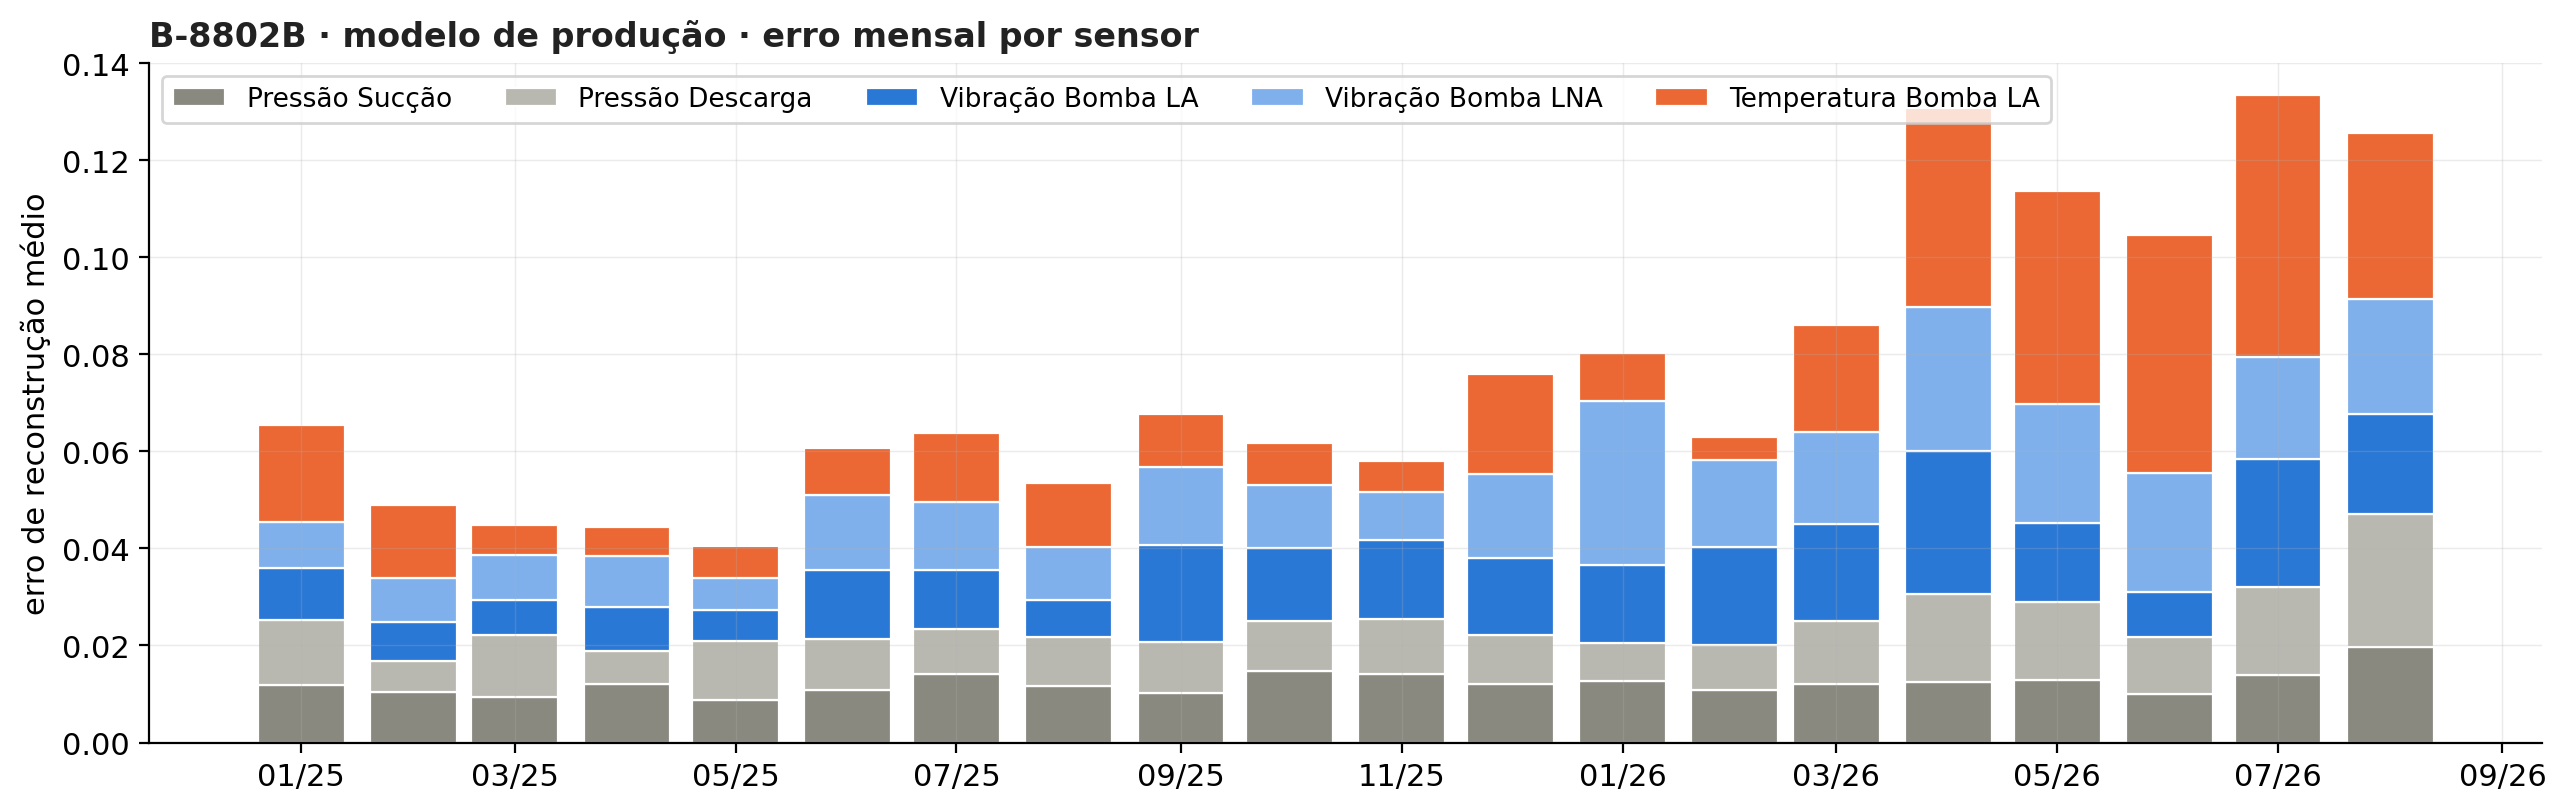

In [2]:
si = fx.si; b = fx.BUNDLE
raw = si.carregar_dados(fx.CFG["data_new"])
X = si.preprocessar(b, raw); m = si.carregar_modelo(b)
with torch.no_grad():
    x = torch.tensor(X.values, dtype=torch.float32); r = m(x)[0]
S = pd.DataFrame(((r - x) ** 2).numpy() / X.shape[1], index=X.index, columns=X.columns)
mes = S.resample("MS").mean()
cores_s = ["#8a897f", "#b9b8b0", "#2a78d6", "#7fb0ec", "#eb6834"]
fig, ax = plt.subplots(figsize=(13, 4.2))
base_ = np.zeros(len(mes))
for c, cor in zip(mes.columns, cores_s):
    ax.bar(mes.index, mes[c], bottom=base_, width=24, color=cor, label=c, edgecolor="white", lw=0.8)
    base_ += mes[c].values
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
ax.set_ylabel("erro de reconstrução médio")
ax.legend(ncol=5, fontsize=9.5, loc="upper left")
estilo(ax, "B-8802B · modelo de produção · erro mensal por sensor")
fig.tight_layout()

parc = pd.DataFrame({p: (S.loc[p].sum() / S.loc[p].values.sum() * 100).round(0) for p in ["2025", "2026"]})
parc.columns = ["% do erro em 2025", "% do erro em 2026"]; parc

**Leitura:** em 2025 cada sensor responde por ~20% do erro. Em abr–ago/2026 o erro total dobra e a parcela da
**temperatura do mancal LA** fica ~9× maior (o mancal esfriou para ~45 °C, abaixo do que o treino viu): a suspeita do
efeito sazonal da temperatura se confirma. Correlação do erro com o nível da temperatura: −0,35 (mais frio → mais erro).

## 2. Resumo por variante (mediana dos 6 modelos)

- **erro 2026/2025**: erro médio em abr–ago/2026 ÷ erro médio em 2025 (1 = estável; quanto maior, mais o modelo "estranha"
  2026 sem que nada tenha quebrado);
- **oscilação**: desvio da variação de 5 em 5 min ÷ desvio do score;
- **âncora 17/01**: quantos dos 6 modelos alertam no episódio conhecido de 17/01/2026;
- **sintética**: casos detectados antes do fim da rampa / casos válidos, somando os 6 modelos (100% e 50% de intensidade).

In [3]:
s100 = [c for c in av if c.startswith("sint100")]; s50 = [c for c in av if c.startswith("sint50")]
av["s100_ok"] = (av[s100] > 0).sum(axis=1); av["s100_n"] = av[s100].notna().sum(axis=1)
av["s50_ok"] = (av[s50] > 0).sum(axis=1); av["s50_n"] = av[s50].notna().sum(axis=1)
av["s100_h"] = av[s100].where(av[s100] > -99).median(axis=1)
g = av.merge(ep[["variante", "cand", "modo", "ancora_17jan"]], on=["variante", "cand", "modo"])
res = g.groupby(["variante", "modo"]).agg(
    entradas=("n_entradas", "first"), erro_26_25=("erro_2026T2T3/2025", "median"), oscilacao=("rugosidade", "median"),
    alerta_janmai26=("alerta_jan-mai26_%", "median"), alerta_junago26=("alerta_jun-ago26_%", "median"),
    episodios_2026=("episodios_2026", "median"), ancora=("ancora_17jan", "sum"),
    falha2022_d=("falha2022_dias", "median"), s100_ok=("s100_ok", "sum"), s100_n=("s100_n", "sum"),
    s50_ok=("s50_ok", "sum"), s50_n=("s50_n", "sum"), antecedencia_h=("s100_h", "median"))
tab = pd.DataFrame({
    "entradas": res.entradas, "erro 2026/2025": res.erro_26_25.round(2), "oscilação": res.oscilacao.round(2),
    "alerta jan–mai/26 (%)": res.alerta_janmai26.round(3), "alerta jun–ago/26 (%)": res.alerta_junago26.round(3),
    "episódios 2026": res.episodios_2026, "âncora 17/01": res.ancora.astype(str) + "/6",
    "falha 2022 (dias)": res.falha2022_d.round(1),
    "sintética 100%": res.s100_ok.astype(str) + "/" + res.s100_n.astype(str),
    "sintética 50%": res.s50_ok.astype(str) + "/" + res.s50_n.astype(str),
    "antecedência sintética (h)": res.antecedencia_h.round(0)})
tab.index = [f"{NOMES[v]} · {m}" for v, m in tab.index]
tab

,entradas,erro 2026/2025,oscilação,alerta jan–mai/26 (%),alerta jun–ago/26 (%),episódios 2026,âncora 17/01,falha 2022 (dias),sintética 100%,sintética 50%,antecedência sintética (h)
"base (5 sensores, como produção) · bruto",5,1.79,0.68,0.037,0.000,1.0,4/6,2.1,18/18,11/18,21.0
"base (5 sensores, como produção) · suave",5,1.92,0.16,0.201,0.005,4.0,6/6,2.1,17/17,12/17,23.0
base + espectro/desvio das vibrações · bruto,13,2.77,0.32,0.072,1.083,10.5,0/6,2.1,3/12,0/12,-12.0
base + espectro/desvio das vibrações · suave,13,2.79,0.10,0.916,3.227,41.5,0/6,2.1,9/12,1/12,10.0
vib+press + ΔT 30 min/2 h · bruto,6,1.09,0.72,0.004,0.000,0.5,3/6,2.0,8/18,2/18,4.0
vib+press + ΔT 30 min/2 h · suave,6,1.11,0.18,0.115,0.022,3.0,6/6,2.1,18/18,12/18,21.0
vib+press + T − mediana 3 d · bruto,5,1.12,0.73,0.080,0.000,2.5,5/6,2.1,15/18,10/18,19.0
vib+press + T − mediana 3 d · suave,5,1.16,0.18,0.303,0.000,4.0,6/6,2.1,16/18,14/18,22.0
só temperaturas · bruto,4,3.94,0.13,0.551,0.180,9.5,1/6,2.0,0/18,0/18,-22.0
só temperaturas · suave,4,3.95,0.07,0.583,0.222,12.0,1/6,2.0,0/17,0/17,-20.0


## 3. O erro fica estável em 2026?

Erro mensal ÷ erro médio de 2025, um modelo por variante (semente 0, taxa 1e-4, score bruto). Linha em 1 = o modelo
vê 2026 como viu 2025.

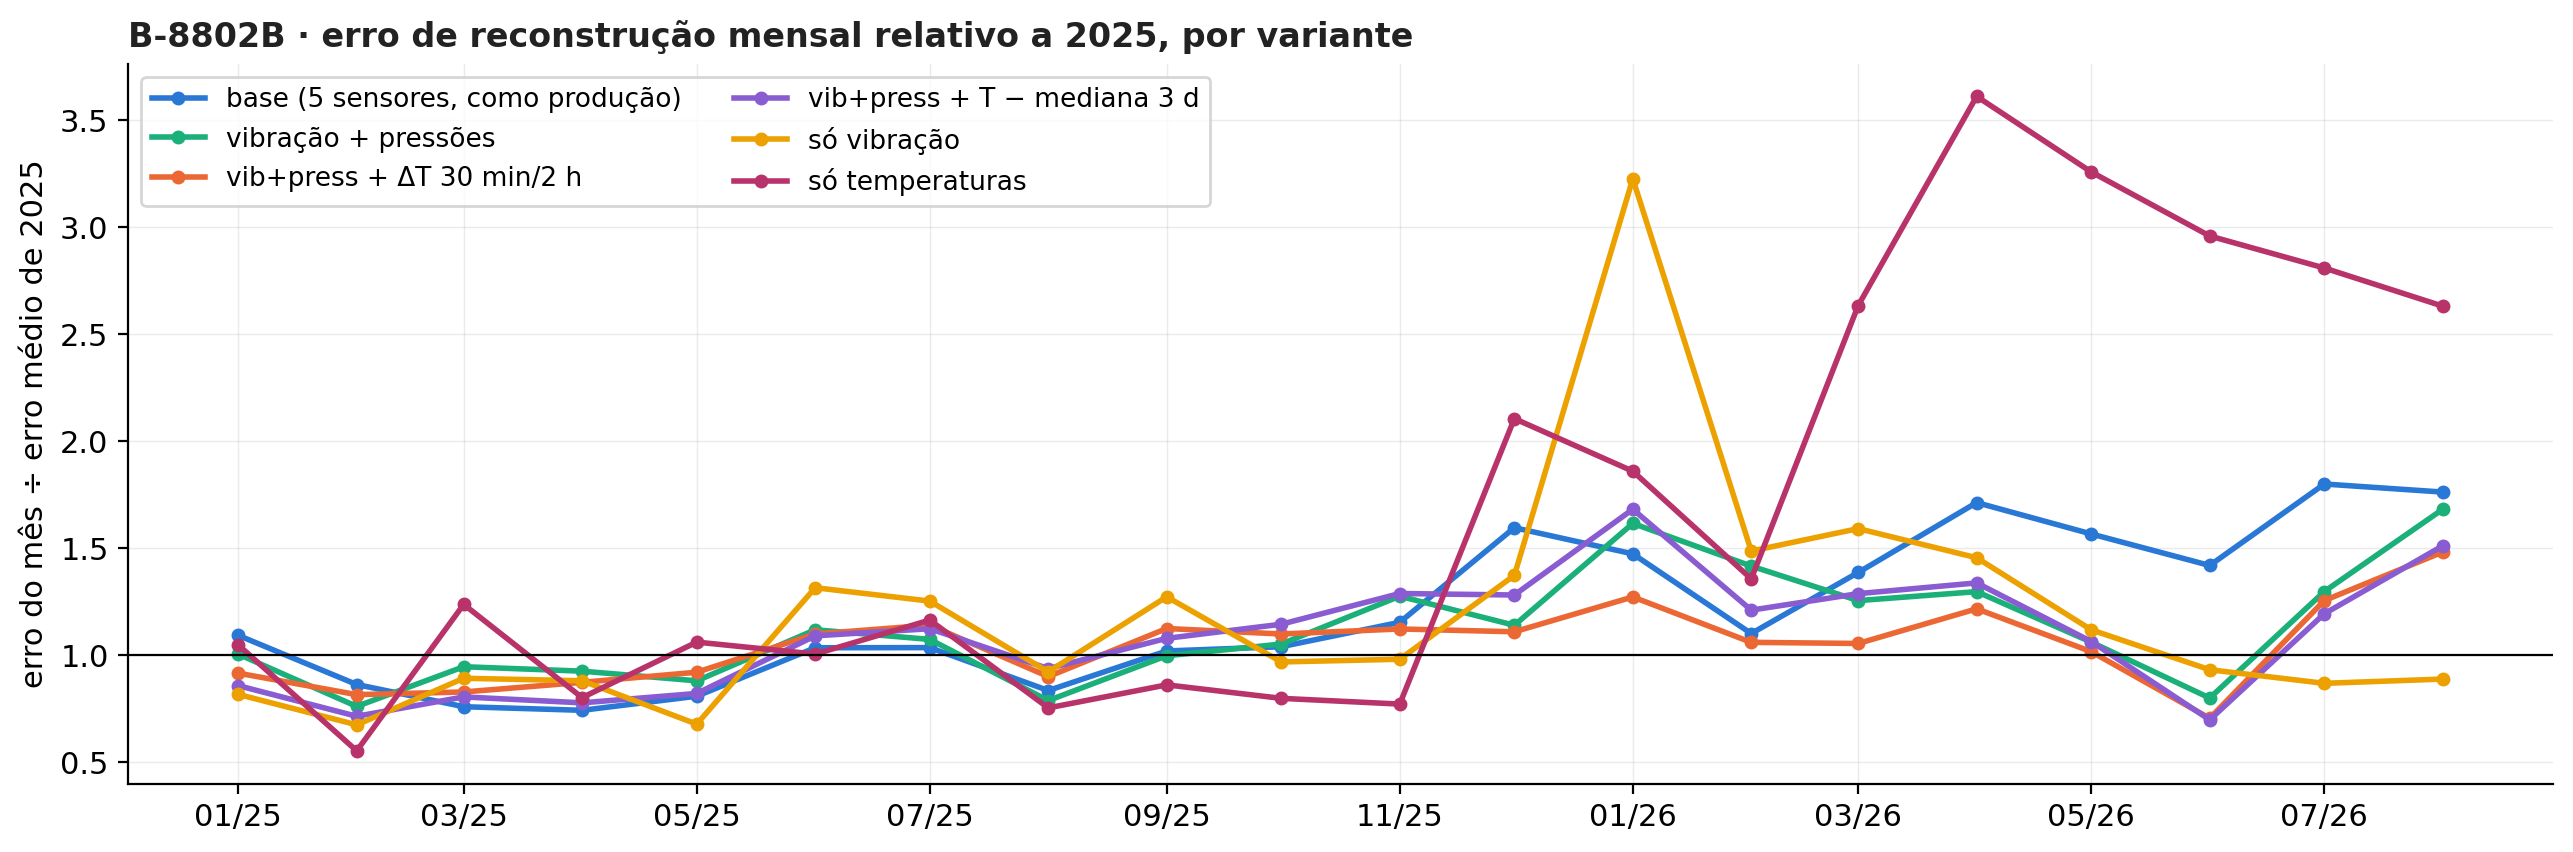

In [4]:
fig, ax = plt.subplots(figsize=(13, 4.4))
for v in ["base", "vib_press", "temp_delta", "temp_rel", "vib", "temps"]:
    e = pd.read_parquet(R / "scores" / f"{v}__l128-64-32_lat16_lr0.0001_s0.parquet").score
    mm = e.resample("MS").mean() / e.loc["2025"].mean()
    ax.plot(mm.index, mm.values, marker="o", ms=4, lw=2, color=CORES[v], label=NOMES[v])
ax.axhline(1, color="black", lw=0.8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
ax.set_ylabel("erro do mês ÷ erro médio de 2025")
ax.legend(fontsize=9.5, ncol=2)
estilo(ax, "B-8802B · erro de reconstrução mensal relativo a 2025, por variante")
fig.tight_layout()

**Leitura:** base e "só temperaturas" sobem junto com o esfriamento de abr–jul/2026; as variantes sem o nível da
temperatura ficam perto de 1. Em ago/2026 todas sobem para ~1,5×: aí o erro vem da pressão de descarga (ver a figura
da seção 1), não da temperatura. "Só vibração" tem o pico de jan/2026 (episódios de 10–17/01).

## 4. Suavizar o score (mediana móvel de 1 h)

Uma semana de abril/2026, modelo base: o score bruto e o suavizado, cada um com o seu limiar (μ+6,5σ de 2025).

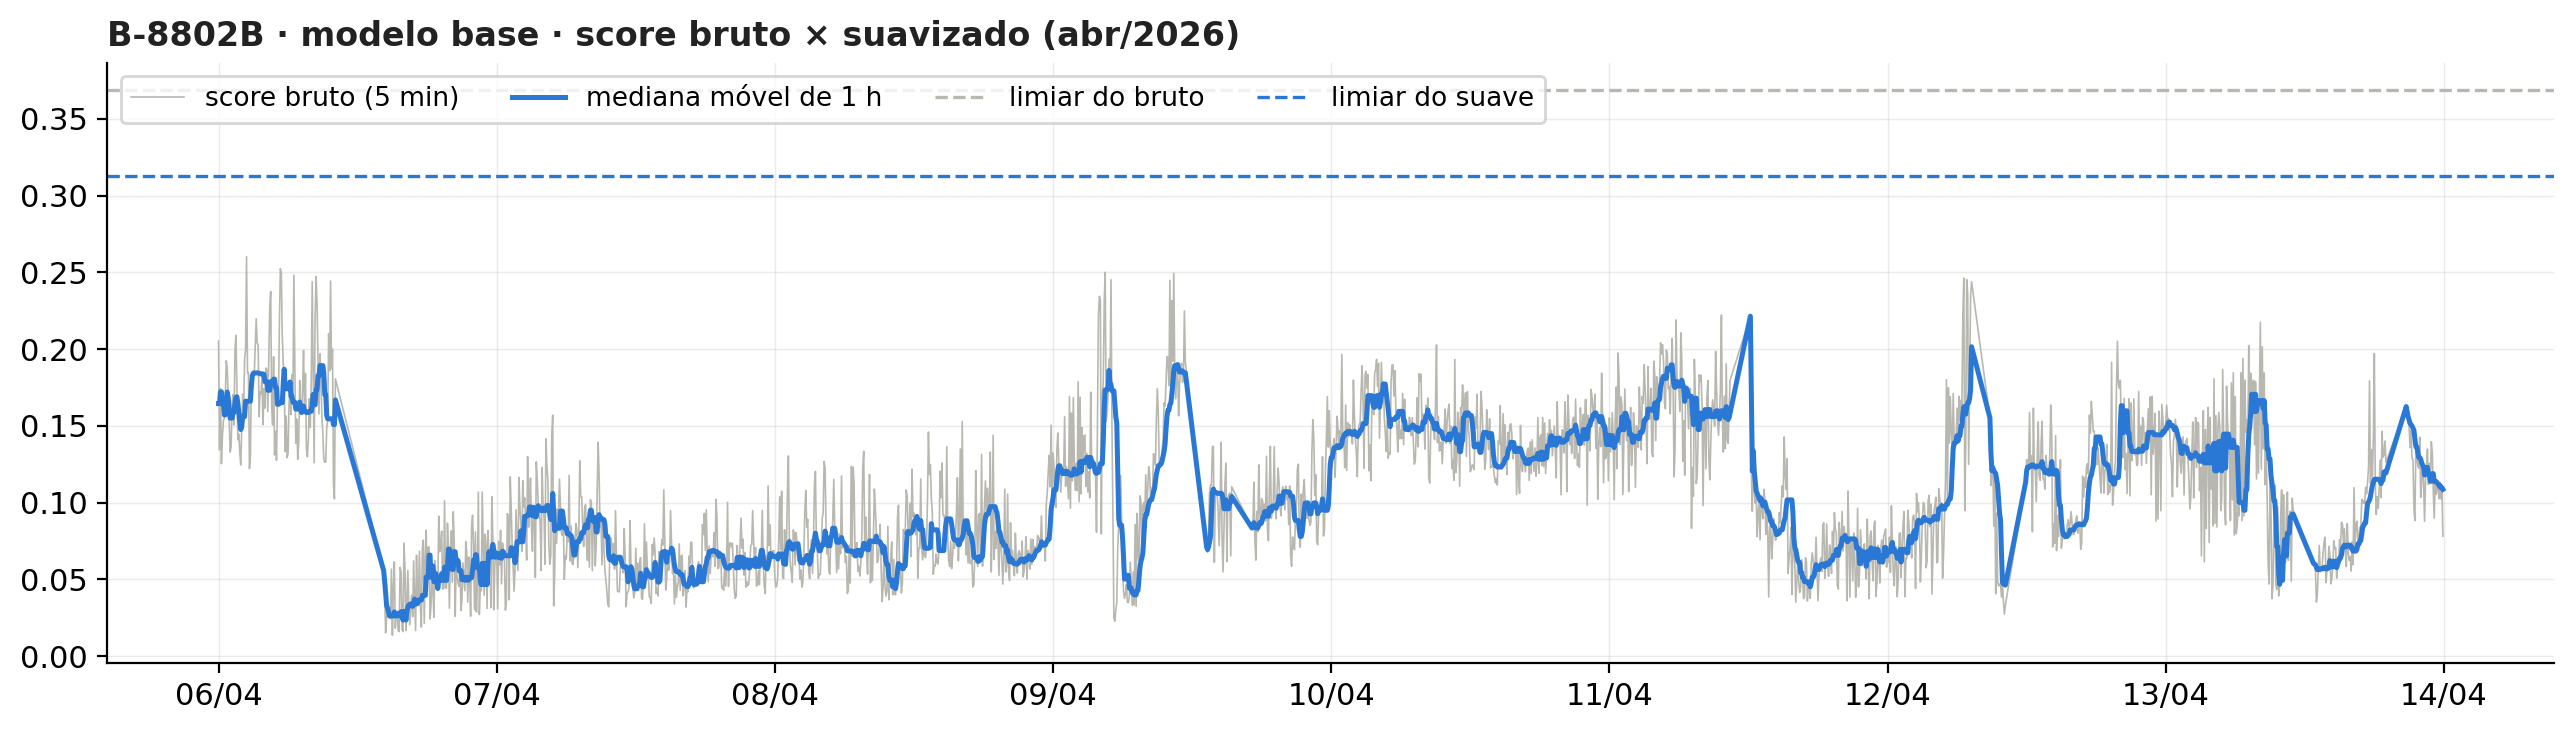

In [5]:
e = pd.read_parquet(R / "scores" / "base__l128-64-32_lat16_lr0.0001_s0.parquet").score
sm = fx.suavizar(e)
thr = {k: s.loc["2025"].mean() + 6.5 * s.loc["2025"].std() for k, s in [("bruto", e), ("suave", sm)]}
w = slice("2026-04-06", "2026-04-13")
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(e.loc[w].index, e.loc[w].values, lw=0.6, color="#b9b8b0", label="score bruto (5 min)")
ax.plot(sm.loc[w].index, sm.loc[w].values, lw=1.8, color="#2a78d6", label="mediana móvel de 1 h")
ax.axhline(thr["bruto"], color="#b9b8b0", ls="--", lw=1.2, label="limiar do bruto")
ax.axhline(thr["suave"], color="#2a78d6", ls="--", lw=1.2, label="limiar do suave")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.legend(fontsize=9.5, ncol=4, loc="upper left")
estilo(ax, "B-8802B · modelo base · score bruto × suavizado (abr/2026)")
fig.tight_layout()

**Leitura:** a mediana de 1 h tira ~75% da oscilação (coluna "oscilação" cai de ~0,7 para ~0,16) e o gráfico fica
muito mais legível. Mas, com o limiar recalculado como μ+6,5σ, o desvio do score suave é menor e o limiar desce junto:
o número de episódios em 2026 **sobe** (base: 1 → 4) e a detecção fica parecida. Suavizar serve para a visualização e
para a operação ler a tendência; para alarmar menos, o limiar do score suave precisa ser calibrado de outro jeito
(por exemplo, pelo mesmo número de alertas em 2025), não por μ+6,5σ.

## 5. Alerta × sensibilidade, modelo a modelo

Cada ponto é um modelo (score bruto): episódios de alerta em 2026 (sem falha conhecida, exceto a âncora de 17/01) ×
casos da falha sintética detectados antes do fim da rampa (100% e 50%, de 6 possíveis). O ideal é o canto **superior
esquerdo**.

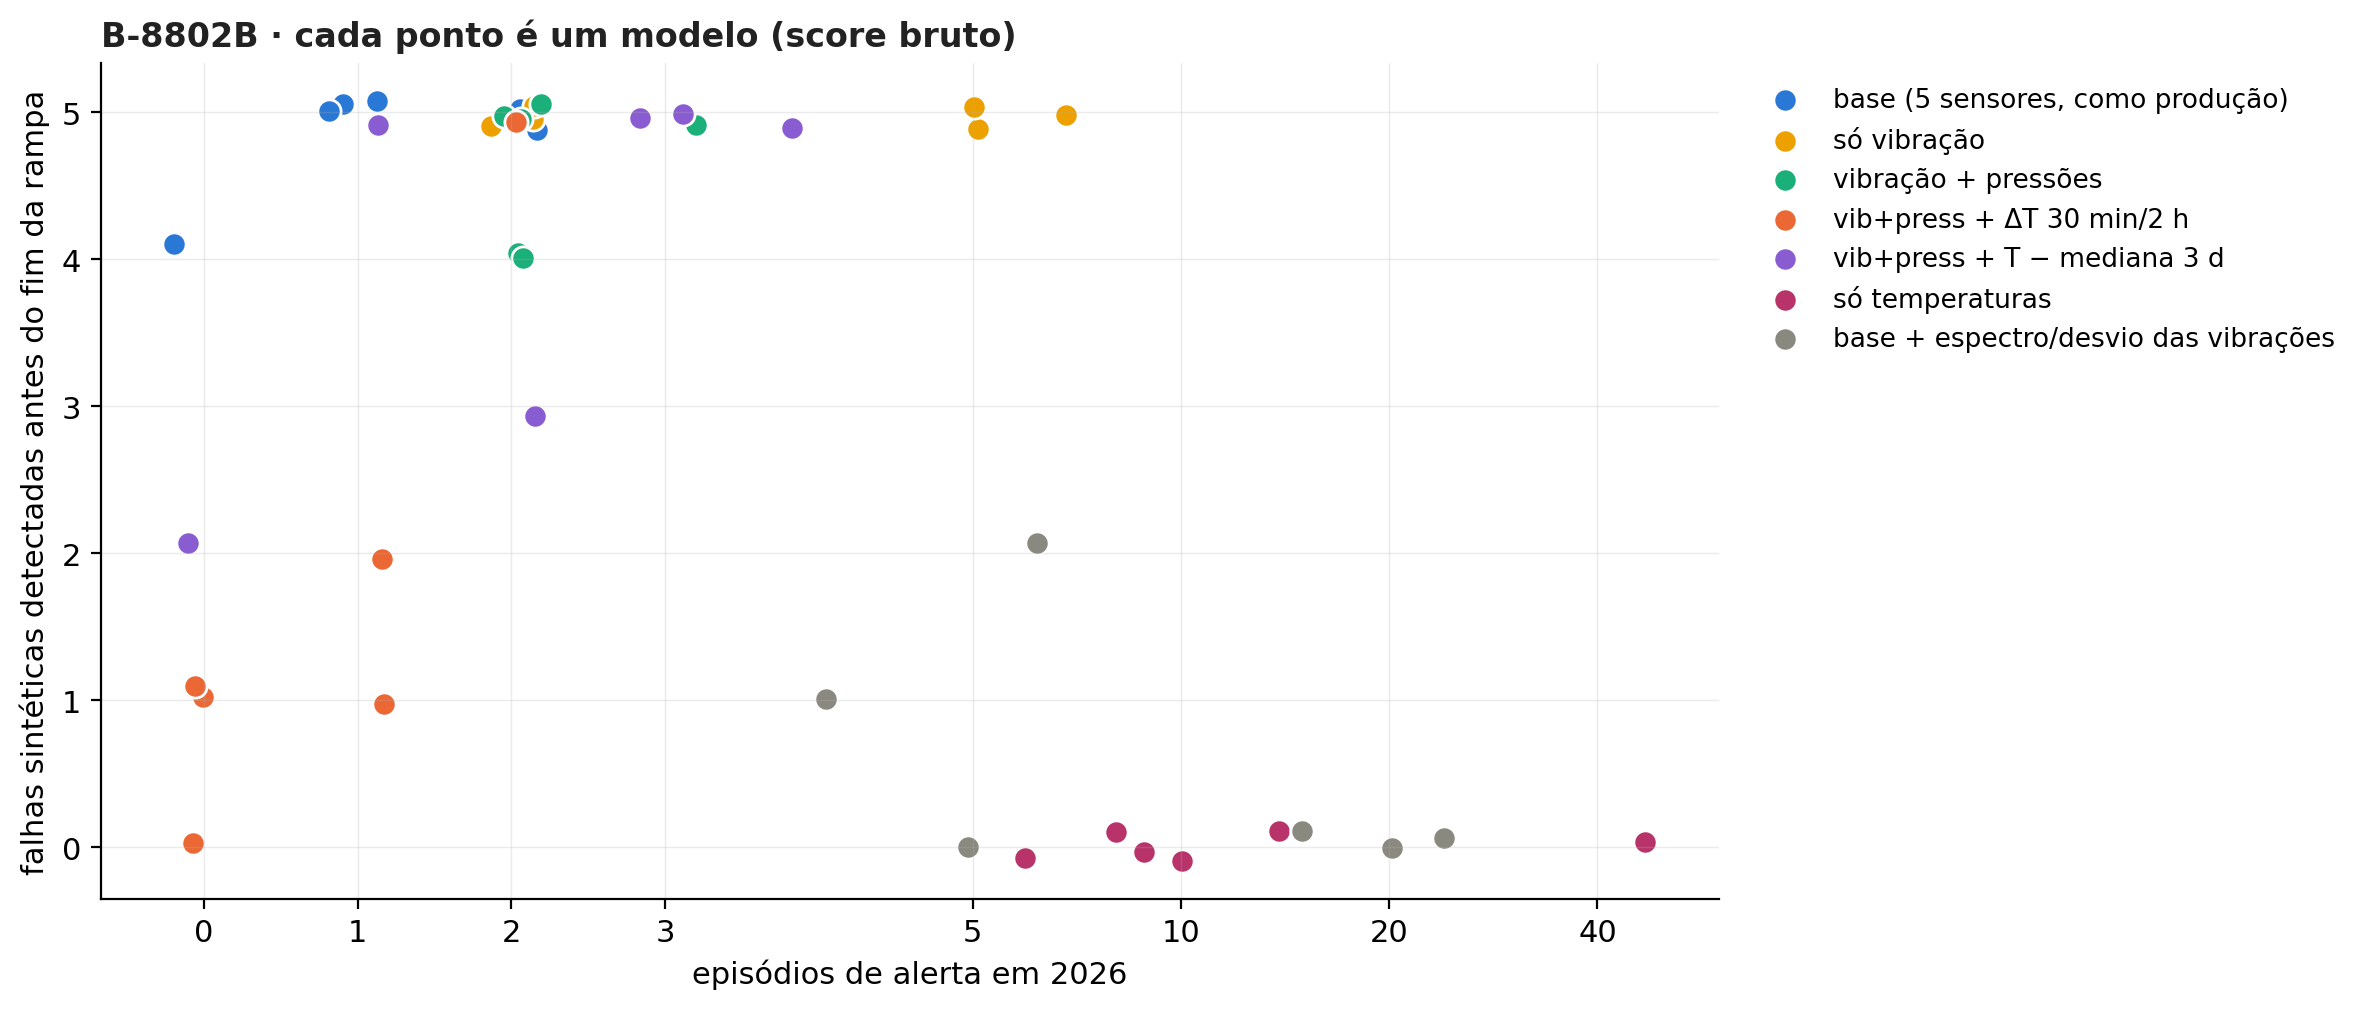

In [6]:
gb = g[g.modo == "bruto"].copy(); gb["sint_ok"] = gb.s100_ok + gb.s50_ok
fig, ax = plt.subplots(figsize=(12, 5.2))
rng = np.random.default_rng(0)
for v in NOMES:
    d = gb[gb.variante == v]
    ax.scatter(d.episodios_2026 + rng.uniform(-0.2, 0.2, len(d)), d.sint_ok + rng.uniform(-0.12, 0.12, len(d)),
               s=70, color=CORES[v], edgecolor="white", lw=1, label=NOMES[v])
ax.set_xscale("symlog", linthresh=5)
ax.set_xticks([0, 1, 2, 3, 5, 10, 20, 40]); ax.xaxis.set_major_formatter(plt.ScalarFormatter())
ax.set_xlabel("episódios de alerta em 2026"); ax.set_ylabel("falhas sintéticas detectadas antes do fim da rampa")
ax.legend(fontsize=9.5, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
estilo(ax, "B-8802B · cada ponto é um modelo (score bruto)")
fig.tight_layout()

## 6. E uma falha só térmica?

Tirar a temperatura do modelo só seria um problema se ele hoje percebesse uma falha térmica. Teste: a parte térmica da
assinatura de 2022 (mancal LA +6,7 °C, e os outros mancais) em rampa de 48 h, sem mudar vibração nem pressões, a 1× e a
2× (+13,4 °C), nas 3 datas válidas. Contagem: detectados / casos válidos, somando os 6 modelos.

In [7]:
linhas = {}
for (v, m), d in te.groupby(["variante", "modo"]):
    r = {}
    for k in (1, 2):
        c = [x for x in d if x.startswith(f"termica{k}x")]
        r[f"+{6.7 * k:.1f} °C: detecta"] = f"{int((d[c] > -99).sum().sum())}/{int(d[c].notna().sum().sum())}"
        r[f"+{6.7 * k:.1f} °C: antes do fim da rampa"] = int((d[c] > 0).sum().sum())
    linhas[f"{NOMES[v]} · {m}"] = r
pd.DataFrame(linhas).T

,+6.7 °C: detecta,+6.7 °C: antes do fim da rampa,+13.4 °C: detecta,+13.4 °C: antes do fim da rampa
"base (5 sensores, como produção) · bruto",0/18,0,1/18,0
"base (5 sensores, como produção) · suave",0/17,0,5/17,0
vib+press + ΔT 30 min/2 h · bruto,0/18,0,0/18,0
vib+press + ΔT 30 min/2 h · suave,0/18,0,0/18,0
vib+press + T − mediana 3 d · bruto,0/18,0,0/18,0
vib+press + T − mediana 3 d · suave,0/18,0,2/18,0
só vibração · bruto,0/18,0,0/18,0
só vibração · suave,0/16,0,0/16,0
vibração + pressões · bruto,0/18,0,0/18,0
vibração + pressões · suave,0/18,0,0/18,0


**Leitura:** nem o modelo de produção (base) percebe uma falha só térmica: 0 de 18 a +6,7 °C e quase nada a
+13,4 °C. A temperatura de 2025 varia ~20 °C entre estações, então uma subida de 7–13 °C em 2 dias cabe no "normal"
do VAE. Hoje a temperatura entra no modelo quase só como **fonte de erro sazonal**, não como sensibilidade. Uma falha
térmica precisa de um detector próprio (ex.: o resíduo de temperatura M8 do monitor, ou uma regra de taxa de subida).

## 7. Retreino completo: com temperatura × sem temperatura

Até aqui eram 6 modelos por variante e uma régua simplificada. Agora, o **pipeline de retreino completo** (grade de 4
configurações × 3 sementes = 12 modelos por receita) e a **régua exata de produção** (bundle + `simpred_inference`, com
a regra de 1 h). Receitas:
- **modelo atual**: os 5 sensores (com a temperatura do mancal LA);
- **sem temperatura · VAE**: vibrações + pressões;
- **sem temperatura · denso**: as mesmas entradas, com um autoencoder denso (gargalo de 2–3) no lugar do VAE.

Cada linha do gráfico abaixo é um modelo; a faixa colorida marca quando ele está em **alerta**. Em cima, os sensores.

In [8]:
import sys as _s; _s.path.insert(0, str(RAIZ / "src"))
from transpetro_modelos.drift import battery
ctx = fx.contexto()
RECEITAS = {"modelo atual (com temperatura)": (RAIZ / "results/vp_vs_nivel/bundles/nivel", "#2a78d6"),
            "sem temperatura · VAE": (RAIZ / "results/vp_vs_nivel/bundles/vp", "#1baf7a"),
            "sem temperatura · denso": (RAIZ / "results/vpd/bundles/vpd", "#eb6834")}
RECEITAS = {k: v for k, v in RECEITAS.items() if v[0].exists()}
cache = RAIZ / "results/vp_vs_nivel/alertas_2026.parquet"
alerta = pd.read_parquet(cache) if cache.exists() else pd.DataFrame()
r26 = raw.loc["2025-12-25":]
for nome, (pasta, _) in RECEITAS.items():
    for b in sorted(pasta.iterdir()):
        col = f"{nome}|{b.name}"
        if col not in alerta:
            torch.manual_seed(0)
            f = battery.score(b, r26)["is_anomaly"]
            alerta = alerta.reindex(alerta.index.union(f.index)) if len(alerta) else pd.DataFrame(index=f.index)
            alerta[col] = f.reindex(alerta.index).fillna(False).astype(bool)
alerta = alerta.fillna(False).astype(bool)
alerta.to_parquet(cache)
alerta = alerta.loc["2026-01-01":]
print({k: sum(c.startswith(k) for c in alerta) for k in RECEITAS}, "modelos")

dado 2025-26: 139264 leituras de 5 min com a bomba operando; 2022: 10091


fração do tempo com a bomba operando em cada falha sintética: {'2026-01-25': np.float64(1.0), '2026-03-05': np.float64(0.68), '2026-04-20': np.float64(0.12), '2026-06-10': np.float64(1.0), '2026-07-15': np.float64(1.0)}
{'modelo atual (com temperatura)': 12, 'sem temperatura · VAE': 12, 'sem temperatura · denso': 12} modelos


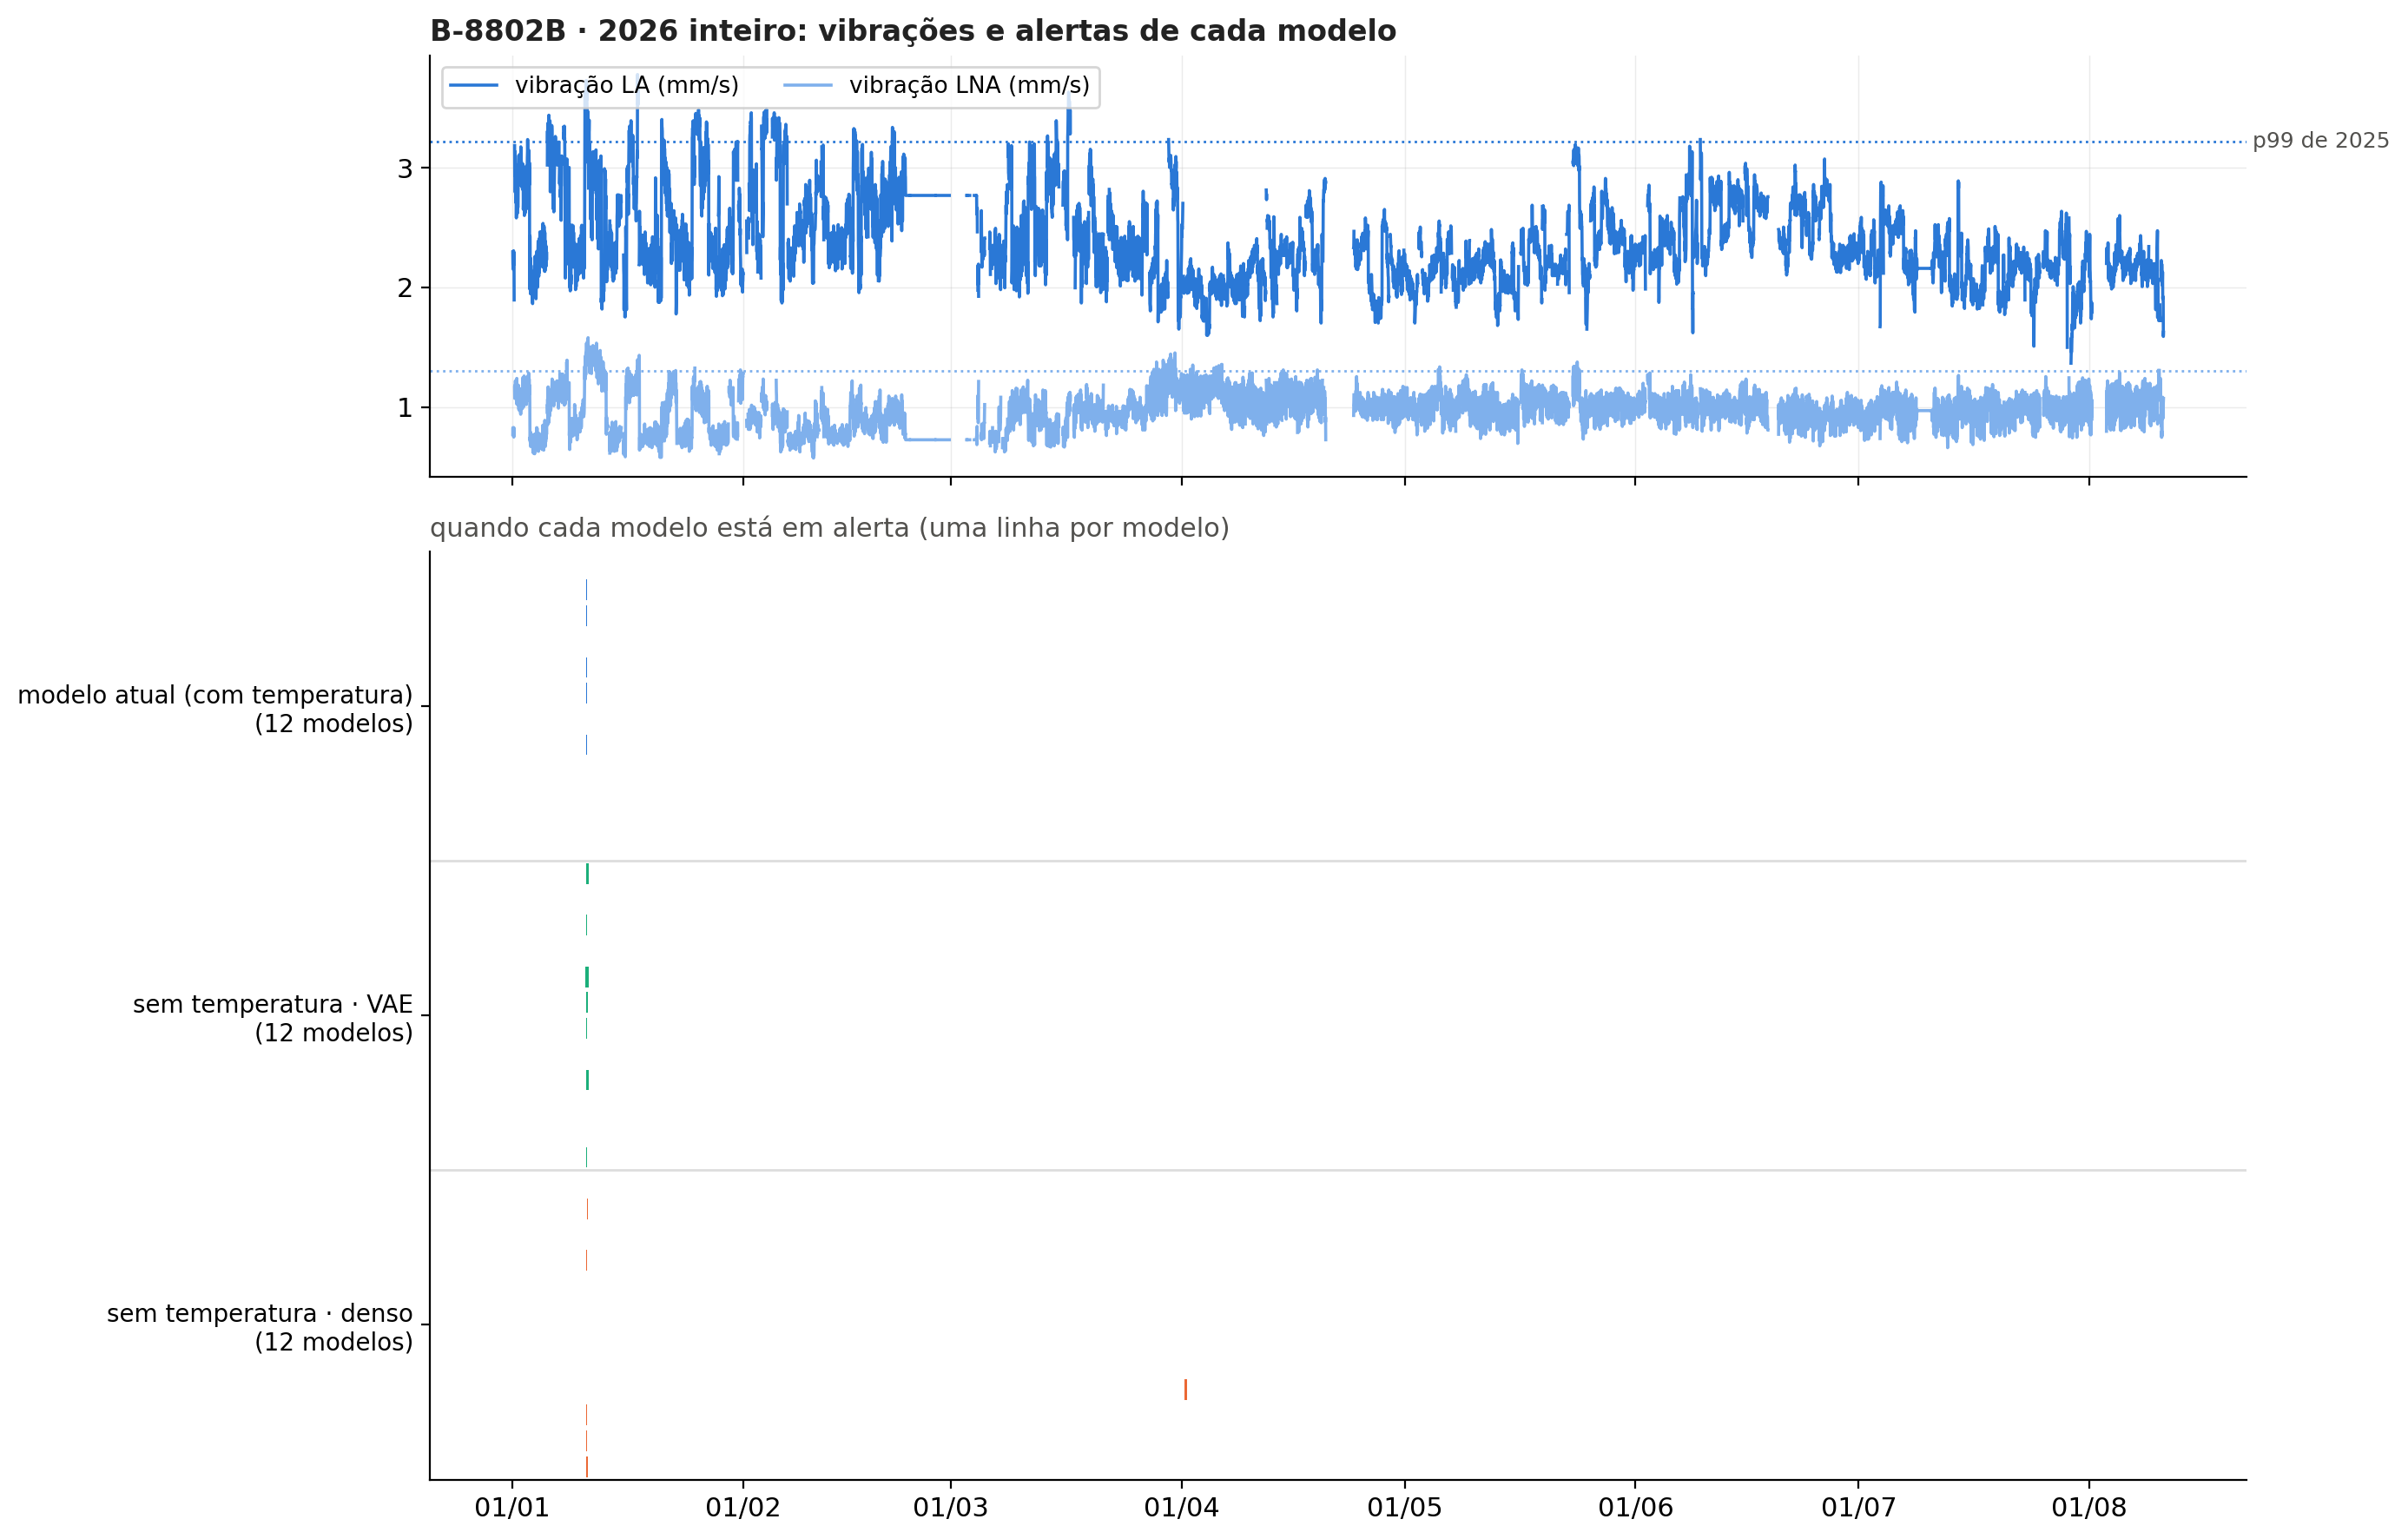

In [9]:
def painel(ini, fim, titulo, altura=9):
    pr = fx.temporal(raw.loc[ini:fim])
    a = alerta.loc[ini:fim]
    n = len(a.columns)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, altura), sharex=True,
                                   gridspec_kw={"height_ratios": [1, 2.2]})
    p99 = fx.temporal(raw.loc["2025"]).quantile(0.99)
    for c, cor, rot in [("Vibração Bomba LA", "#2a78d6", "vibração LA"), ("Vibração Bomba LNA", "#7fb0ec", "vibração LNA")]:
        d = pr[c].resample("30min").median()
        ax1.plot(d.index, d.values, color=cor, lw=1.3, label=f"{rot} (mm/s)")
        ax1.axhline(p99[c], color=cor, ls=":", lw=1)
    ax1.text(1.0, p99["Vibração Bomba LA"], " p99 de 2025", transform=ax1.get_yaxis_transform(), fontsize=9, color=TEXTO, va="center")
    ax1.legend(fontsize=9.5, loc="upper left", ncol=2)
    estilo(ax1, titulo)
    y, ticks, rotulos = 0, [], []
    for nome, (_, cor) in RECEITAS.items():
        cols = [c for c in a.columns if c.startswith(nome)]
        for c in cols:
            on = a[c]
            blocos = on.ne(on.shift()).cumsum()[on]
            for _, g in on[on].groupby(blocos):
                ax2.barh(y, (g.index[-1] - g.index[0]) + pd.Timedelta("5min"), left=g.index[0], height=0.8, color=cor)
            y += 1
        ticks.append(y - len(cols) / 2 - 0.5); rotulos.append(f"{nome}\n({len(cols)} modelos)")
        ax2.axhline(y - 0.5, color="#dddddd", lw=1); 
    ax2.set_yticks(ticks, rotulos, fontsize=10); ax2.set_ylim(-0.5, y - 0.5); ax2.invert_yaxis()
    ax2.spines[["top", "right"]].set_visible(False)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax2.set_title("quando cada modelo está em alerta (uma linha por modelo)", loc="left", fontsize=11, color=TEXTO)
    fig.tight_layout()

TEXTO = "#52514e"
painel("2026-01-01", "2026-08-10", "B-8802B · 2026 inteiro: vibrações e alertas de cada modelo")

**Leitura:** nas três receitas, **todos os alertas de 2026 caem em janeiro** — de fevereiro a agosto nenhum modelo
alerta. A diferença entre as receitas está só em janeiro. Zoom:

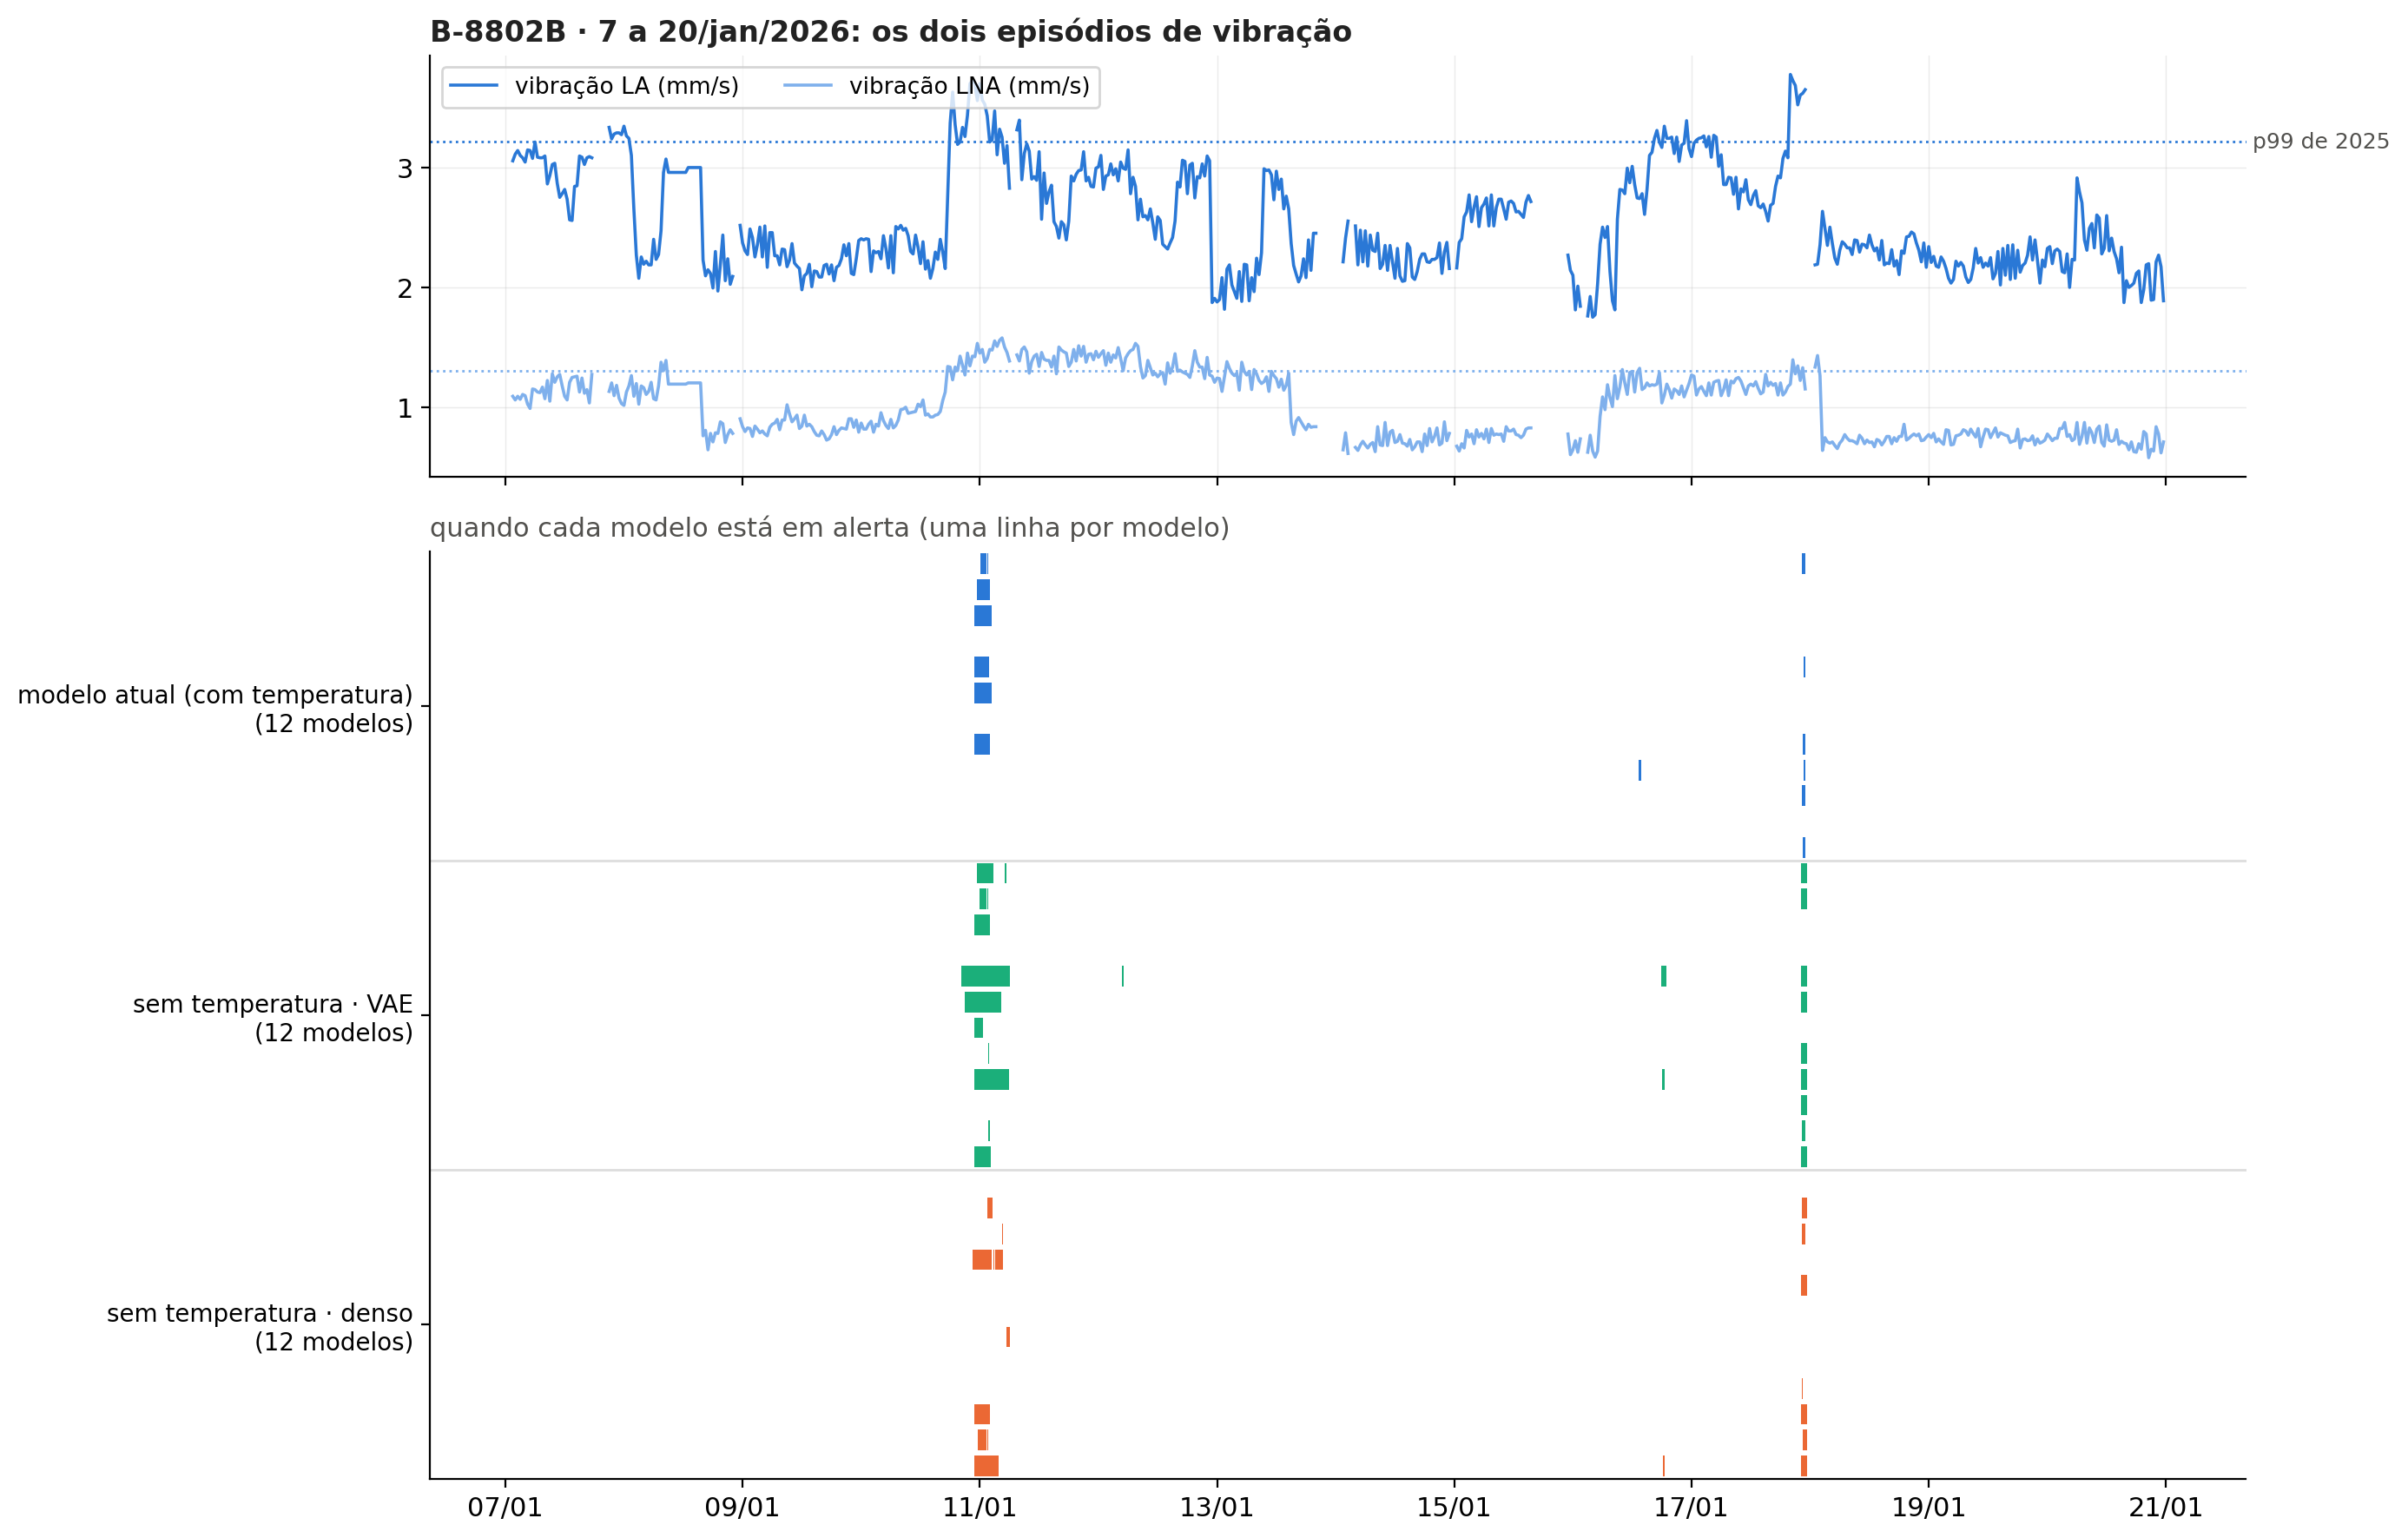

In [10]:
painel("2026-01-07", "2026-01-20", "B-8802B · 7 a 20/jan/2026: os dois episódios de vibração")

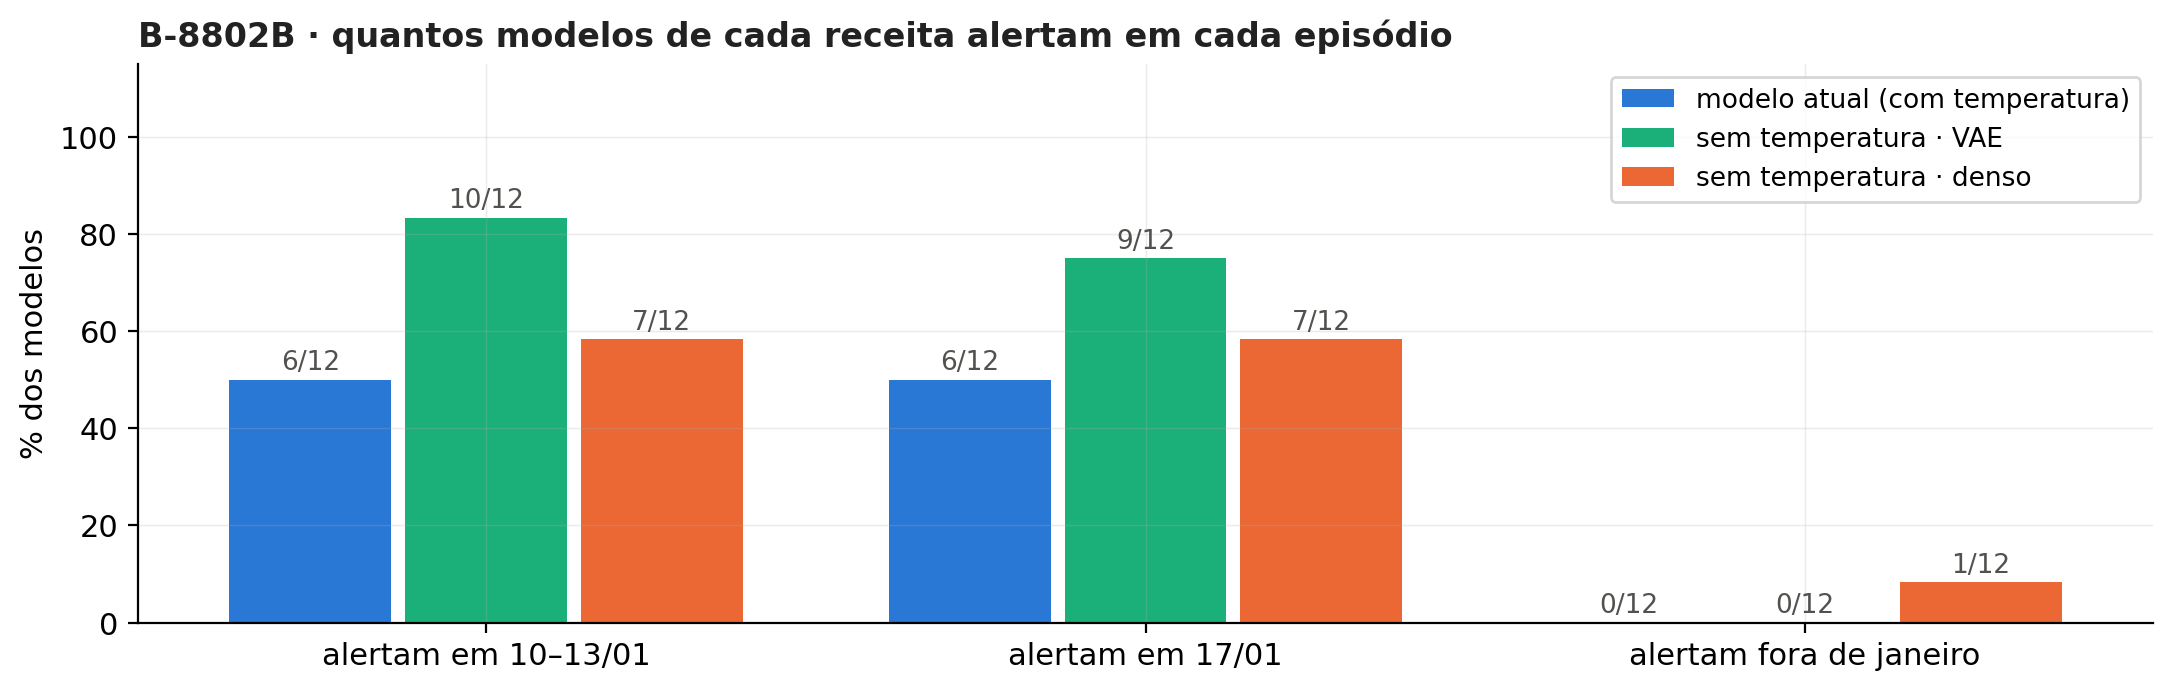

In [11]:
ep = []
for nome in RECEITAS:
    cols = [c for c in alerta.columns if c.startswith(nome)]
    ep.append({"receita": nome,
               "alertam em 10–13/01": sum(alerta.loc["2026-01-10":"2026-01-13", c].any() for c in cols),
               "alertam em 17/01": sum(alerta.loc["2026-01-17 19:30":"2026-01-18 00:40", c].any() for c in cols),
               "alertam fora de janeiro": sum(alerta.loc["2026-02-01":, c].any() for c in cols), "modelos": len(cols)})
ep = pd.DataFrame(ep).set_index("receita")
fig, ax = plt.subplots(figsize=(11, 3.6))
cats = ["alertam em 10–13/01", "alertam em 17/01", "alertam fora de janeiro"]
w = 0.8 / len(ep)
for i, (nome, r) in enumerate(ep.iterrows()):
    x = np.arange(len(cats)) + (i - (len(ep) - 1) / 2) * w
    ax.bar(x, r[cats] / r["modelos"] * 100, width=w * 0.92, color=RECEITAS[nome][1], label=nome)
    for xi, v in zip(x, r[cats]):
        ax.text(xi, v / r["modelos"] * 100 + 2, f"{v}/{r['modelos']}", ha="center", fontsize=9.5, color=TEXTO)
ax.set_xticks(range(len(cats)), cats); ax.set_ylim(0, 115); ax.set_ylabel("% dos modelos")
ax.legend(fontsize=9.5, loc="upper right")
estilo(ax, "B-8802B · quantos modelos de cada receita alertam em cada episódio")
fig.tight_layout()

**O episódio de 10 a 12/01/2026** (zoom acima): a vibração LA fica em 3,3–3,4 mm/s e a LNA em 1,4–1,5 mm/s por
~2 dias — as duas acima do p99 de 2025, e a LNA **mais alta que em 17/01**, o episódio que já tratamos como real
(âncora da bateria). Os modelos sem temperatura alertam nos dois de forma mais consistente. **Se 10–12/01 for um
evento real, a receita sem temperatura é melhor; se não for, ela só alerta mais.** É a pergunta para a operação.

## 8. Sensibilidade: falha de 2022 e falha sintética

Cada ponto é um modelo. À esquerda, quantos dias antes da falha real de 2022 ele alerta; à direita, quantas horas antes
do fim da rampa ele alerta na falha sintética, em cada data de 2026 (valores negativos = alertou depois do fim da rampa;
"não detecta" embaixo).

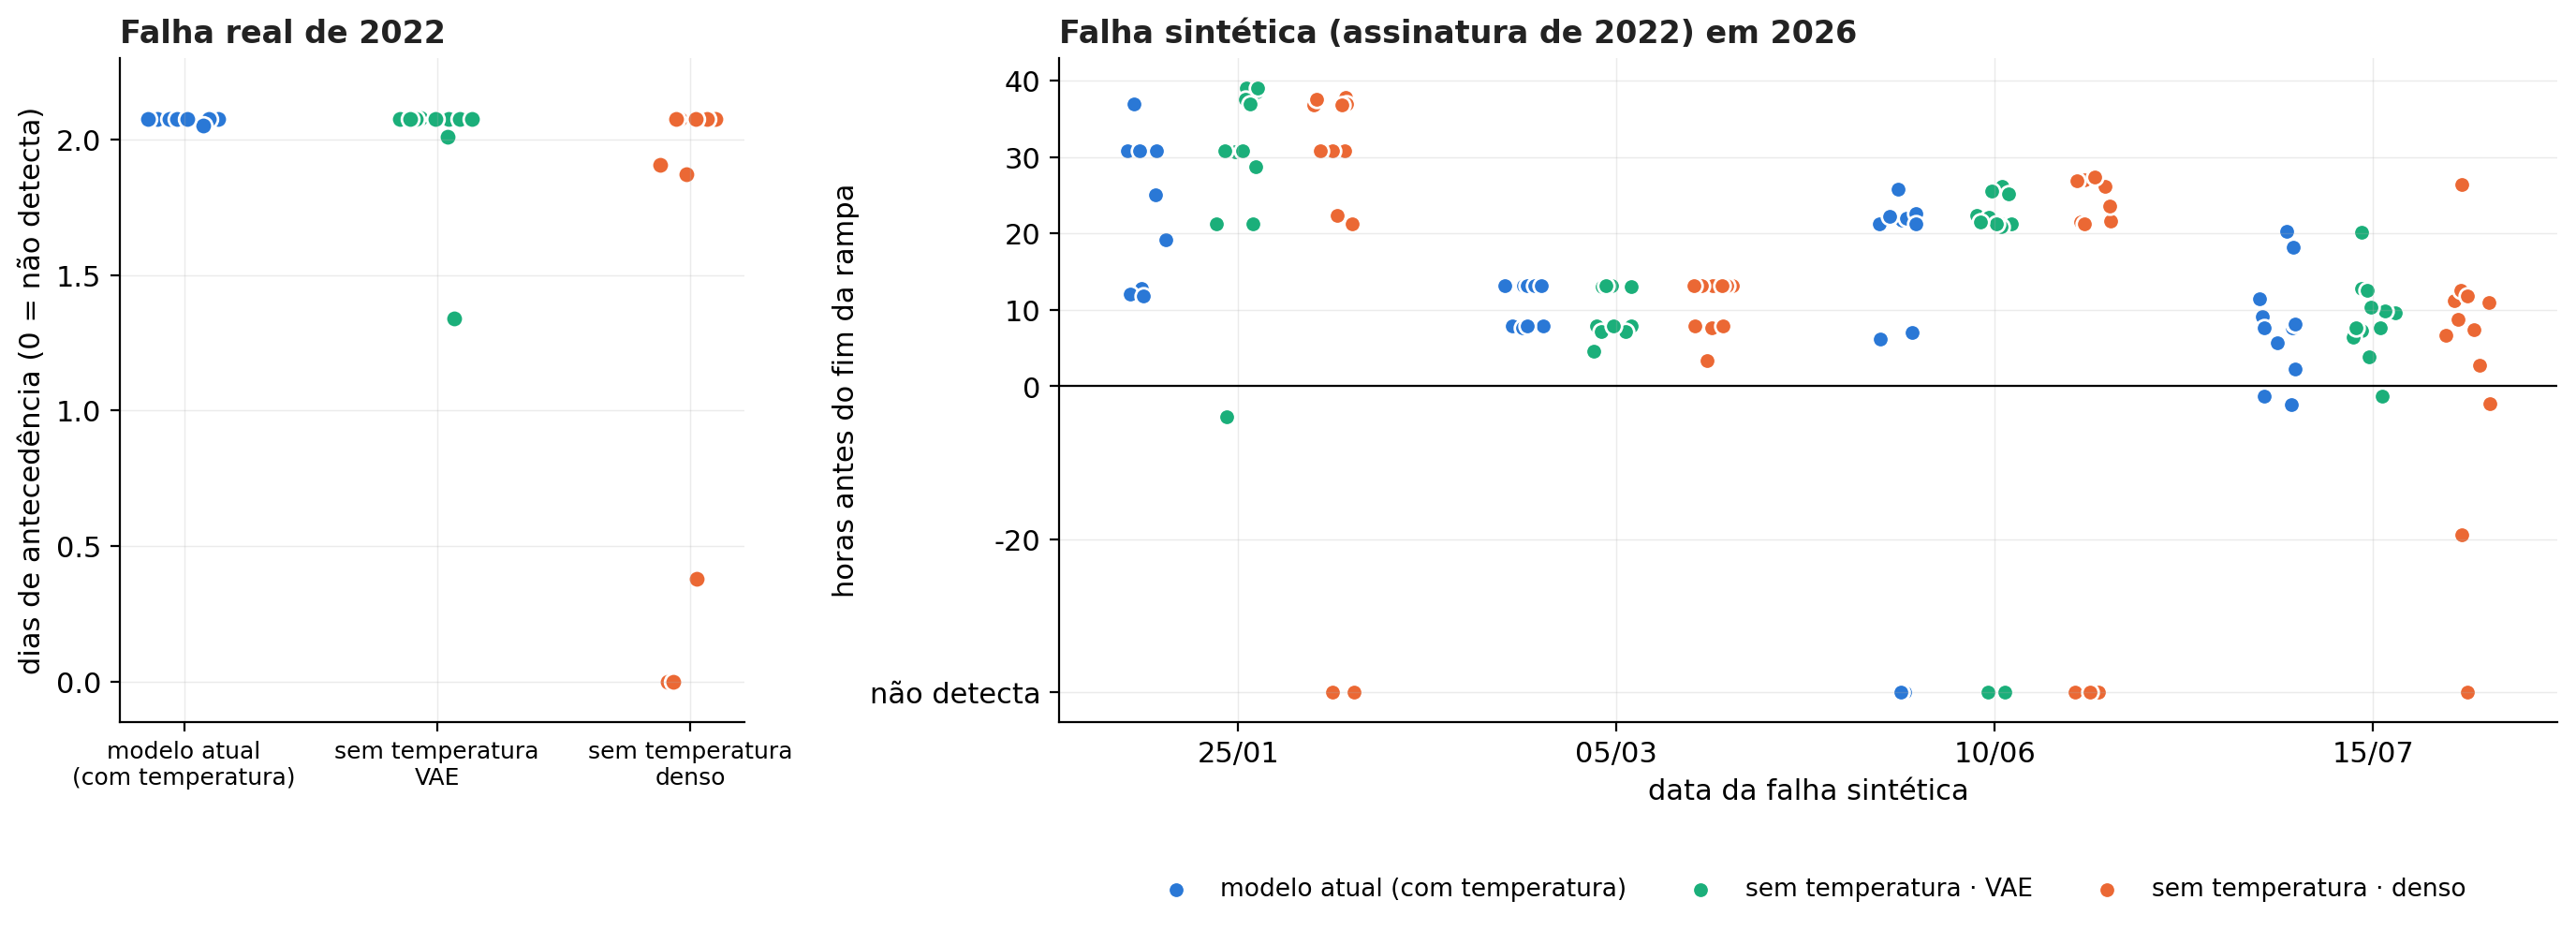

In [12]:
tabs = []
for nome, arq in [("modelo atual (com temperatura)", RAIZ / "results/vp_vs_nivel/avaliacao.csv"),
                  ("sem temperatura · VAE", RAIZ / "results/vp_vs_nivel/avaliacao.csv"),
                  ("sem temperatura · denso", RAIZ / "results/vpd/avaliacao.csv")]:
    if arq.exists():
        d = pd.read_csv(arq)
        var = {"modelo atual (com temperatura)": "nivel", "sem temperatura · VAE": "vp", "sem temperatura · denso": "vpd"}[nome]
        tabs.append(d[d.variante == var].assign(receita=nome))
bat = pd.concat(tabs)
datas = [c for c in bat if c.startswith("sint_") and c.endswith("_h") and bat[c].notna().any()]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 2.4]})
rng = np.random.default_rng(1)
for i, (nome, d) in enumerate(bat.groupby("receita", sort=False)):
    cor = RECEITAS.get(nome, (None, "#8a897f"))[1]
    a1.scatter(np.full(len(d), i) + rng.uniform(-0.15, 0.15, len(d)), d["falha2022_dias"].fillna(0), color=cor, s=45, edgecolor="white")
    for j, c in enumerate(datas):
        contaminada = d.get(c.replace("_h", "_contaminada"), pd.Series(False, index=d.index)).fillna(False).astype(bool)
        v = d.loc[~contaminada, c].fillna(-40)          # sem alerta até o fim do platô = não detecta
        v = v.where(v > -99, -40)
        a2.scatter(np.full(len(v), j) + (i - 1) * 0.25 + rng.uniform(-0.06, 0.06, len(v)), v, color=cor, s=40,
                   edgecolor="white", label=nome if j == 0 else None)
a1.set_xticks(range(bat.receita.nunique()), [n.replace(" (", "\n(").replace(" · ", "\n") for n in bat.receita.unique()], fontsize=9)
a1.set_ylabel("dias de antecedência (0 = não detecta)"); a1.set_ylim(-0.15, 2.3); estilo(a1, "Falha real de 2022")
a2.axhline(0, color="black", lw=0.8)
a2.set_xticks(range(len(datas)), [f"{c[8:10]}/{c[5:7]}" for c in datas])          # sint_MM-DD_h → DD/MM
a2.set_yticks([-40, -20, 0, 10, 20, 30, 40], ["não detecta", "-20", "0", "10", "20", "30", "40"])
a2.set_ylabel("horas antes do fim da rampa"); a2.set_xlabel("data da falha sintética")
a2.legend(fontsize=9.5, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False); estilo(a2, "Falha sintética (assinatura de 2022) em 2026")
fig.tight_layout()

**Leitura:** com VAE, as duas receitas detectam a falha de 2022 com ~2 dias de antecedência e a falha sintética
de forma parecida: tirar a temperatura **não custa sensibilidade**. O **autoencoder denso** (laranja) é menos estável
entre sementes: alguns modelos avisam a falha de 2022 tarde ou não avisam, e perdem datas da sintética. Com 3 sementes
(seção 9) ele parecia tão bom quanto o VAE; com a grade completa, não.

### Perto da falha: os sensores e o score de cada modelo

Como o score se comporta quando a falha se aproxima, e se o modelo **avisa antes**. Em cima, os sensores (mediana de
30 min); embaixo, uma faixa por receita com o score de cada um dos 12 modelos dividido pelo seu limiar (linhas finas;
a grossa é a mediana dos 12). Acima de 1 = acima do limiar. Os pontos marcam **o primeiro alerta** de cada modelo (já
com a persistência e a regra de 1 h de produção).

In [13]:
import json as _json
def score_relativo(bundle, df):
    torch.manual_seed(0)
    r = battery.score(bundle, df)
    thr = _json.loads((bundle / "alarm.json").read_text())["threshold"]
    return r["reconstruction_error"] / thr, r["is_anomaly"]

def painel_falha(df, ini, fim, marcos, titulo, sensores):
    janela = df.loc[ini:fim]
    pr = fx.temporal(janela)
    n = len(RECEITAS)
    fig, axes = plt.subplots(len(sensores) + n, 1, figsize=(14, 2.0 * len(sensores) + 2.4 * n), sharex=True,
                             gridspec_kw={"height_ratios": [1] * len(sensores) + [1.6] * n})
    for ax, (c, rot, cor) in zip(axes, sensores):
        d = pr[c].resample("30min").median()
        ax.plot(d.index, d.values, color=cor, lw=1.4)
        ax.set_ylabel(rot, fontsize=9.5); ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, lw=0.5)
    resumo = []
    for ax, (nome, (pasta, cor)) in zip(axes[len(sensores):], RECEITAS.items()):
        rels, firsts = [], []
        for b in sorted(pasta.iterdir()):
            rel, al = score_relativo(b, janela)
            rel = rel.loc[ini:fim]; al = al.loc[marcos["inicio"]:fim]
            rs = rel.groupby(fx.segmentos(rel.index)).transform(lambda s: s.rolling(12, min_periods=1).median())
            ax.plot(rs.index, rs.values, color=cor, lw=0.6, alpha=0.35)
            rels.append(rs)
            if al.any():
                t = al[al].index.min(); firsts.append(t)
                ax.scatter([t], [rs.asof(t)], color=cor, edgecolor="black", s=40, zorder=4)
        med = pd.concat(rels, axis=1).median(axis=1)
        ax.plot(med.index, med.values, color=cor, lw=2.2)
        ax.axhline(1, color="black", ls="--", lw=1)
        ax.set_ylim(0, max(3, float(np.nanpercentile(med, 99)) * 1.2))
        ant = [(marcos["falha"] - t).total_seconds() / 3600 for t in firsts]
        txt = (f"{len(firsts)}/{len(rels)} modelos alertam · antecedência mediana {np.median(ant):.0f} h antes de "
               f"{marcos['rot_falha']}" if firsts else f"0/{len(rels)} modelos alertam")
        ax.set_title(f"{nome} — {txt}", loc="left", fontsize=10.5, fontweight="bold", color="#222222")
        ax.set_ylabel("score ÷ limiar", fontsize=9.5)
        ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, lw=0.5)
        resumo.append({"receita": nome, "alertam": f"{len(firsts)}/{len(rels)}",
                       "antecedência mediana (h)": round(float(np.median(ant)), 1) if firsts else None})
    for ax in axes:
        ax.axvspan(marcos["inicio"], marcos["falha"], color="#eb6834", alpha=0.07, lw=0)
        ax.axvline(marcos["falha"], color="#b8336a", lw=1.6)
    axes[0].text(marcos["inicio"], 1.04, " início da degradação", transform=axes[0].get_xaxis_transform(), fontsize=9.5, color=TEXTO)
    axes[0].text(marcos["falha"], 1.04, f" {marcos['rot_falha']}", transform=axes[0].get_xaxis_transform(), fontsize=9.5, color="#b8336a")
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=12.5, fontweight="bold")
    fig.tight_layout()
    return pd.DataFrame(resumo).set_index("receita")

SENS = [("Vibração Bomba LA", "vib. LA\n(mm/s)", "#2a78d6"), ("Vibração Bomba LNA", "vib. LNA\n(mm/s)", "#7fb0ec"),
        ("Temperatura Bomba LA", "temp. LA\n(°C)", "#eb6834"), ("Pressão Descarga", "P. descarga\n(bar)", "#8a897f")]

**Falha real de 2022** (trinca nas lâminas do acoplamento, 06/07/2022 10:00). A vibração sobe a partir de 04/07.

,alertam,antecedência mediana (h)
receita,,
modelo atual (com temperatura),12/12,49.8
sem temperatura · VAE,12/12,49.8
sem temperatura · denso,10/12,49.8


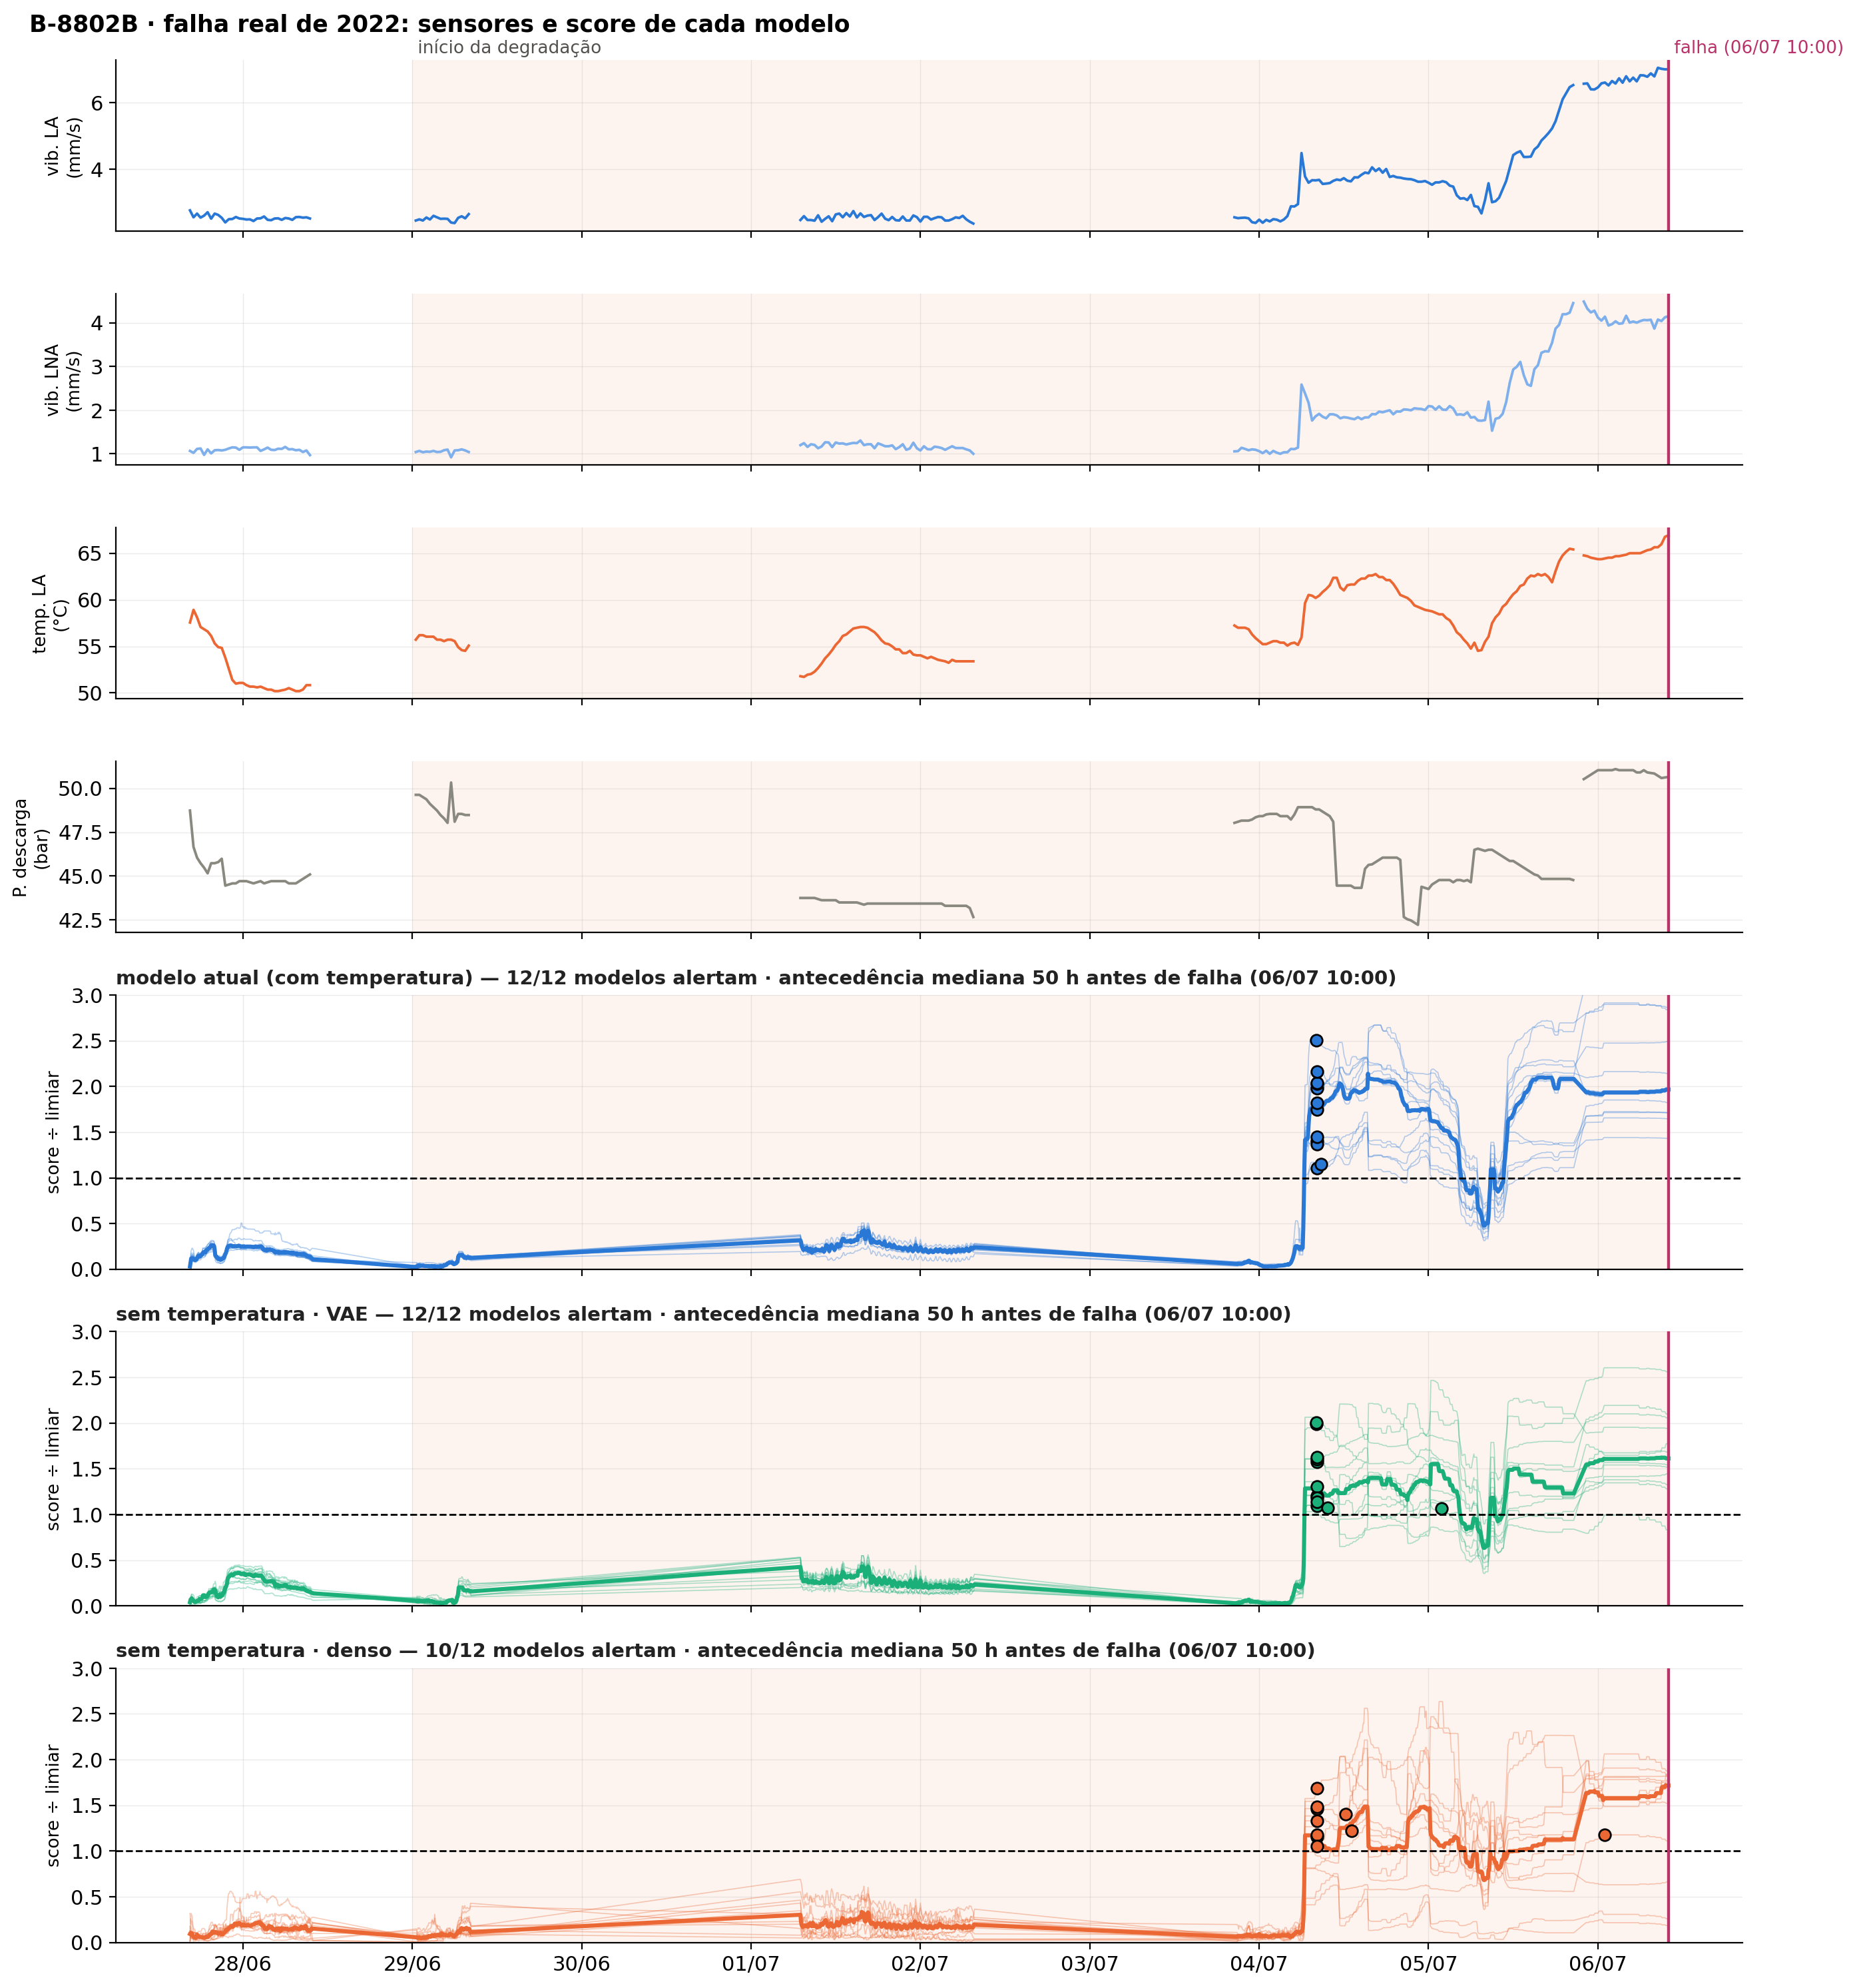

In [14]:
painel_falha(ctx.raw22, "2022-06-27", "2022-07-06 10:00",
             {"inicio": fx.R0, "falha": fx.FAIL, "rot_falha": "falha (06/07 10:00)"},
             "B-8802B · falha real de 2022: sensores e score de cada modelo", SENS)

**Falha sintética em 10/06/2026** (assinatura da falha de 2022 somada ao dado real: rampa de 48 h + 24 h de platô).
Mostra o mesmo teste no regime atual da bomba, que os modelos de 2025 conhecem.

,alertam,antecedência mediana (h)
receita,,
modelo atual (com temperatura),9/12,21.8
sem temperatura · VAE,10/12,21.8
sem temperatura · denso,9/12,23.6


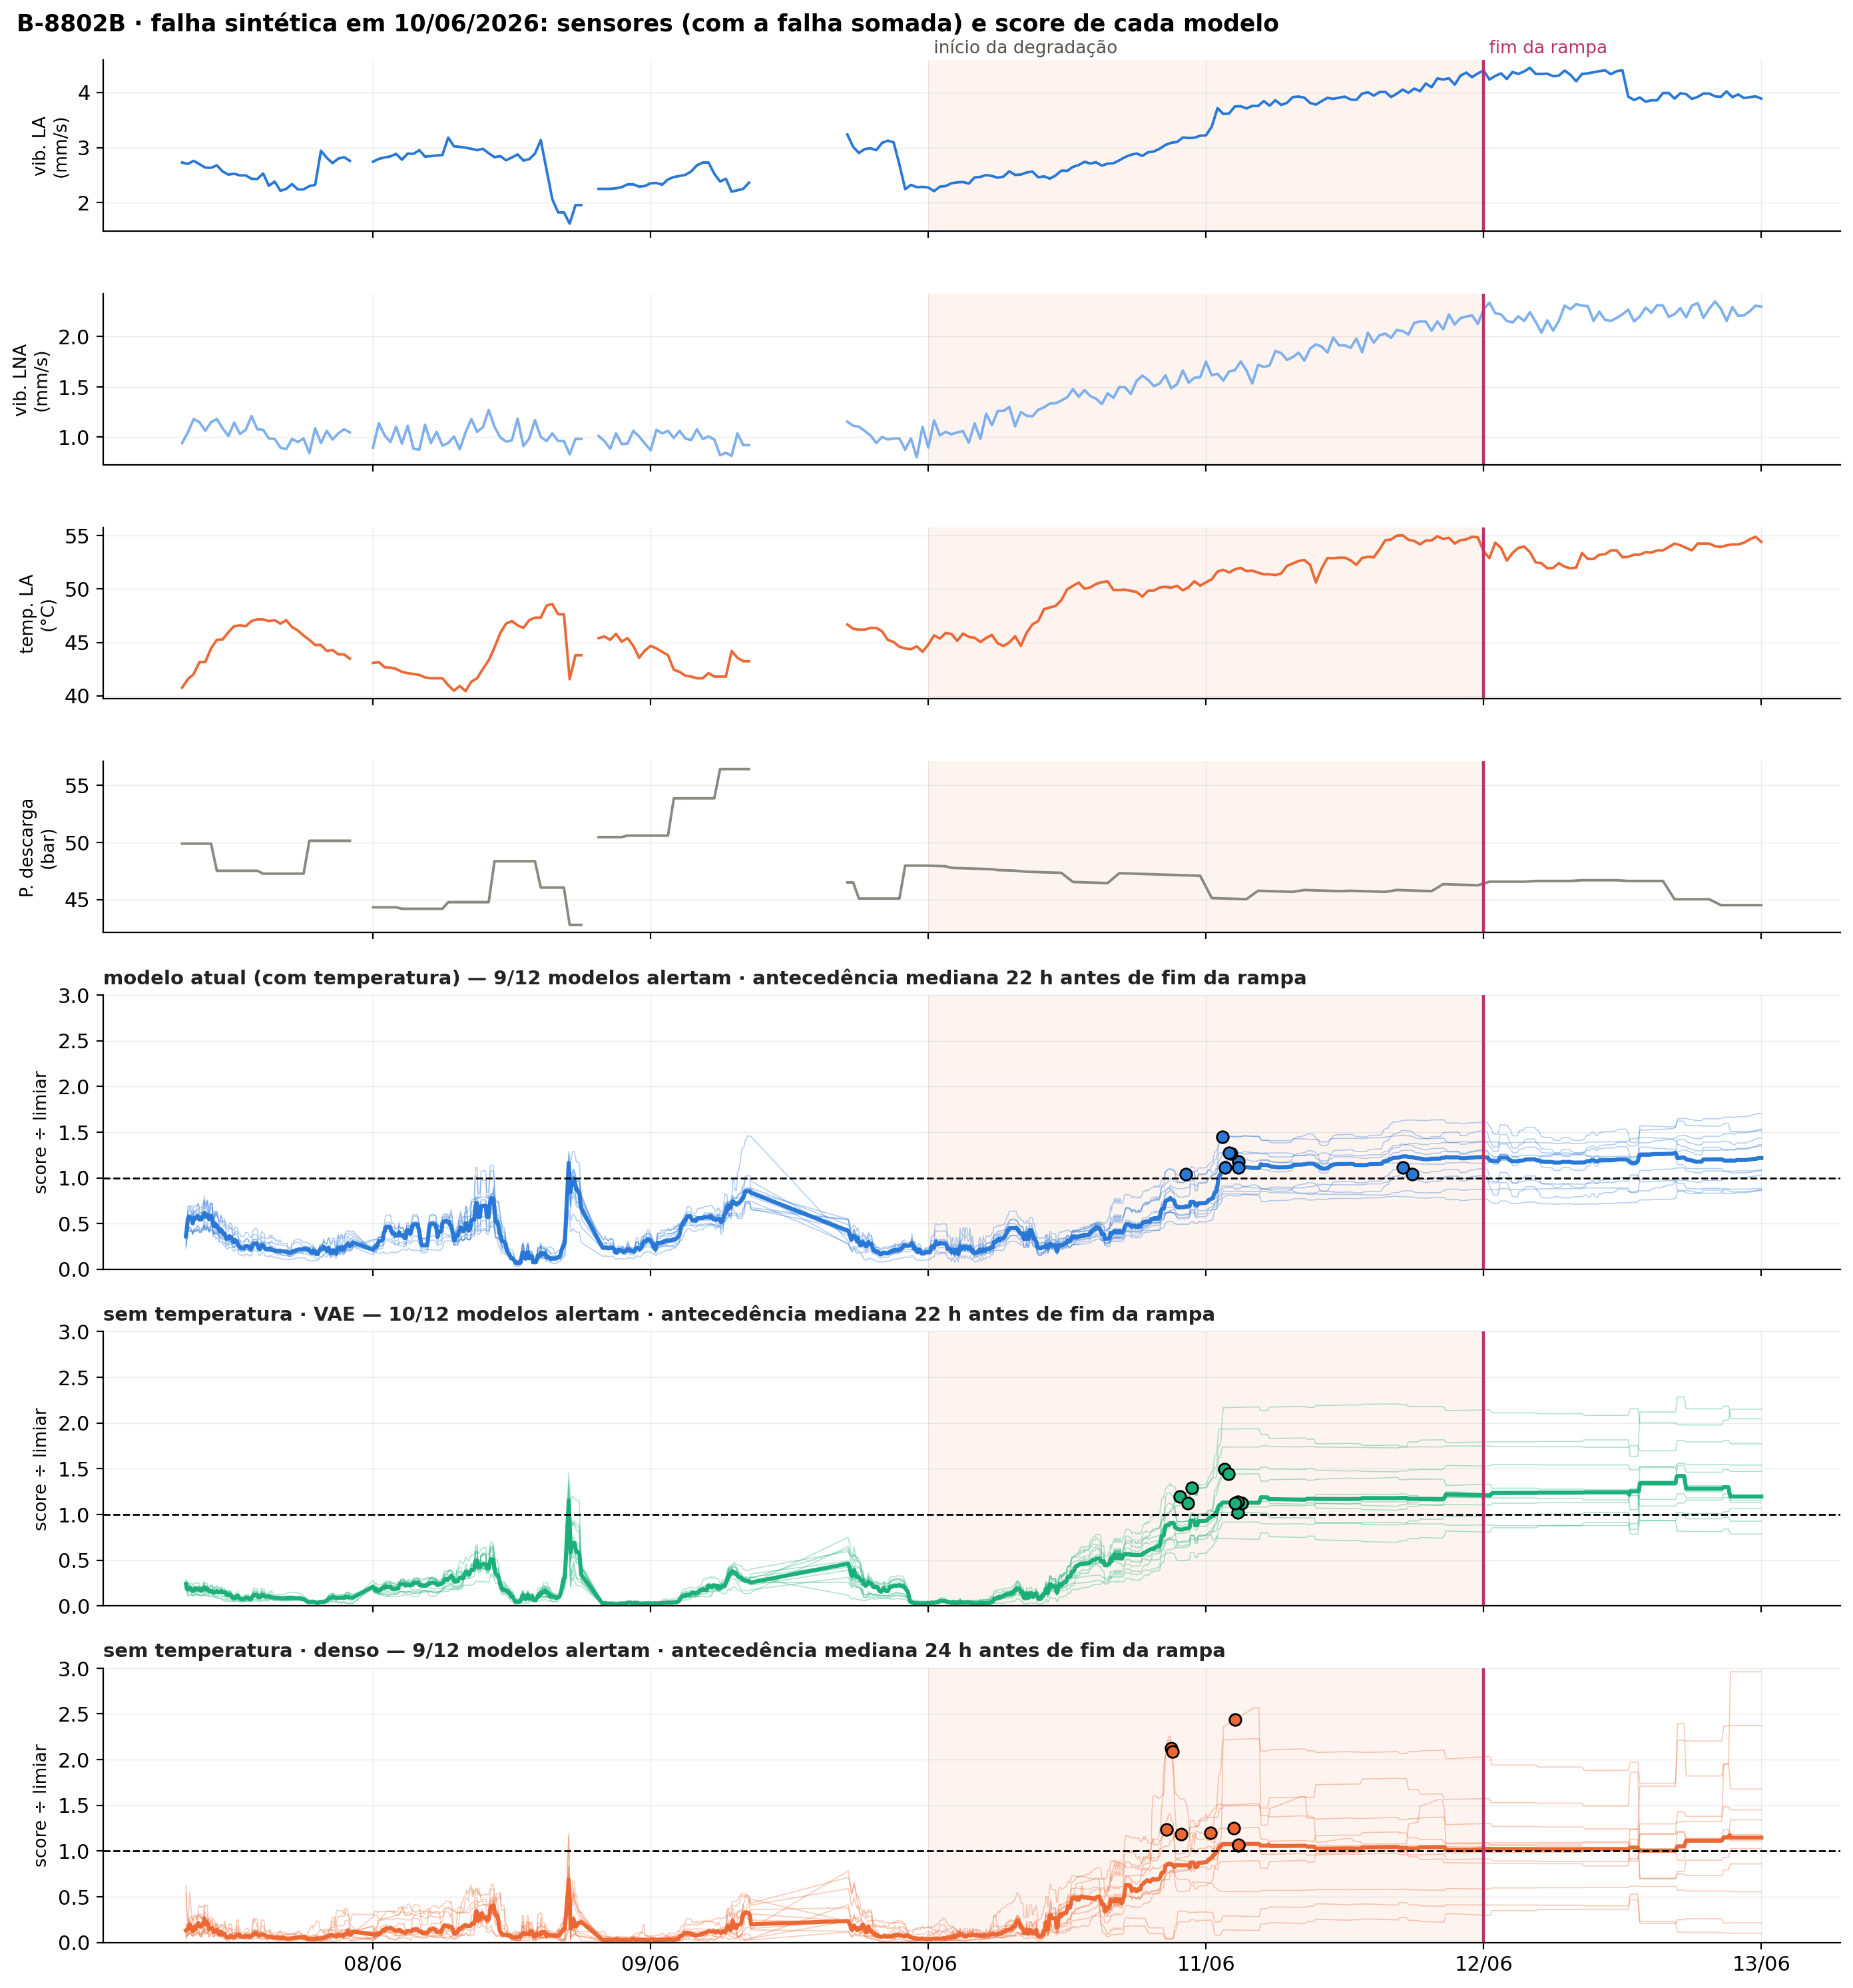

In [15]:
t0 = pd.Timestamp("2026-06-10"); tf = t0 + pd.Timedelta(hours=fx.RAMP)
jan_s = battery.inject(raw.loc[t0 - pd.Timedelta(days=4): tf + pd.Timedelta(hours=fx.HOLD)], fx.SIG, t0, fx.RAMP, fx.HOLD, 1.0)
painel_falha(jan_s, str(t0 - pd.Timedelta(days=3)), str(tf + pd.Timedelta(hours=fx.HOLD)),
             {"inicio": t0, "falha": tf, "rot_falha": "fim da rampa"},
             "B-8802B · falha sintética em 10/06/2026: sensores (com a falha somada) e score de cada modelo", SENS)

**Leitura:** nas duas falhas o score dos modelos que funcionam fica perto de 0,2–0,4 do limiar no normal e sobe
quando a vibração sobe, passando do limiar com folga. Na falha de 2022, o primeiro alerta vem em 04/07, ~2 dias antes
da falha. Sem a temperatura o comportamento é o mesmo — quem puxa o score para cima é a vibração.

## 9. Outras arquiteturas (PCA, autoencoder denso, LSTM e denso com janela de 2 h)

Mesma bateria das seções 2–5. O VAE olha um instante por vez; os modelos "com janela" olham as últimas 2 h. Para ver
o que cada um enxerga, o score de cada arquitetura (sem temperatura) nos 10 dias antes da falha de 2022 — cada score
dividido pelo seu limiar (acima de 1 = acima do limiar).

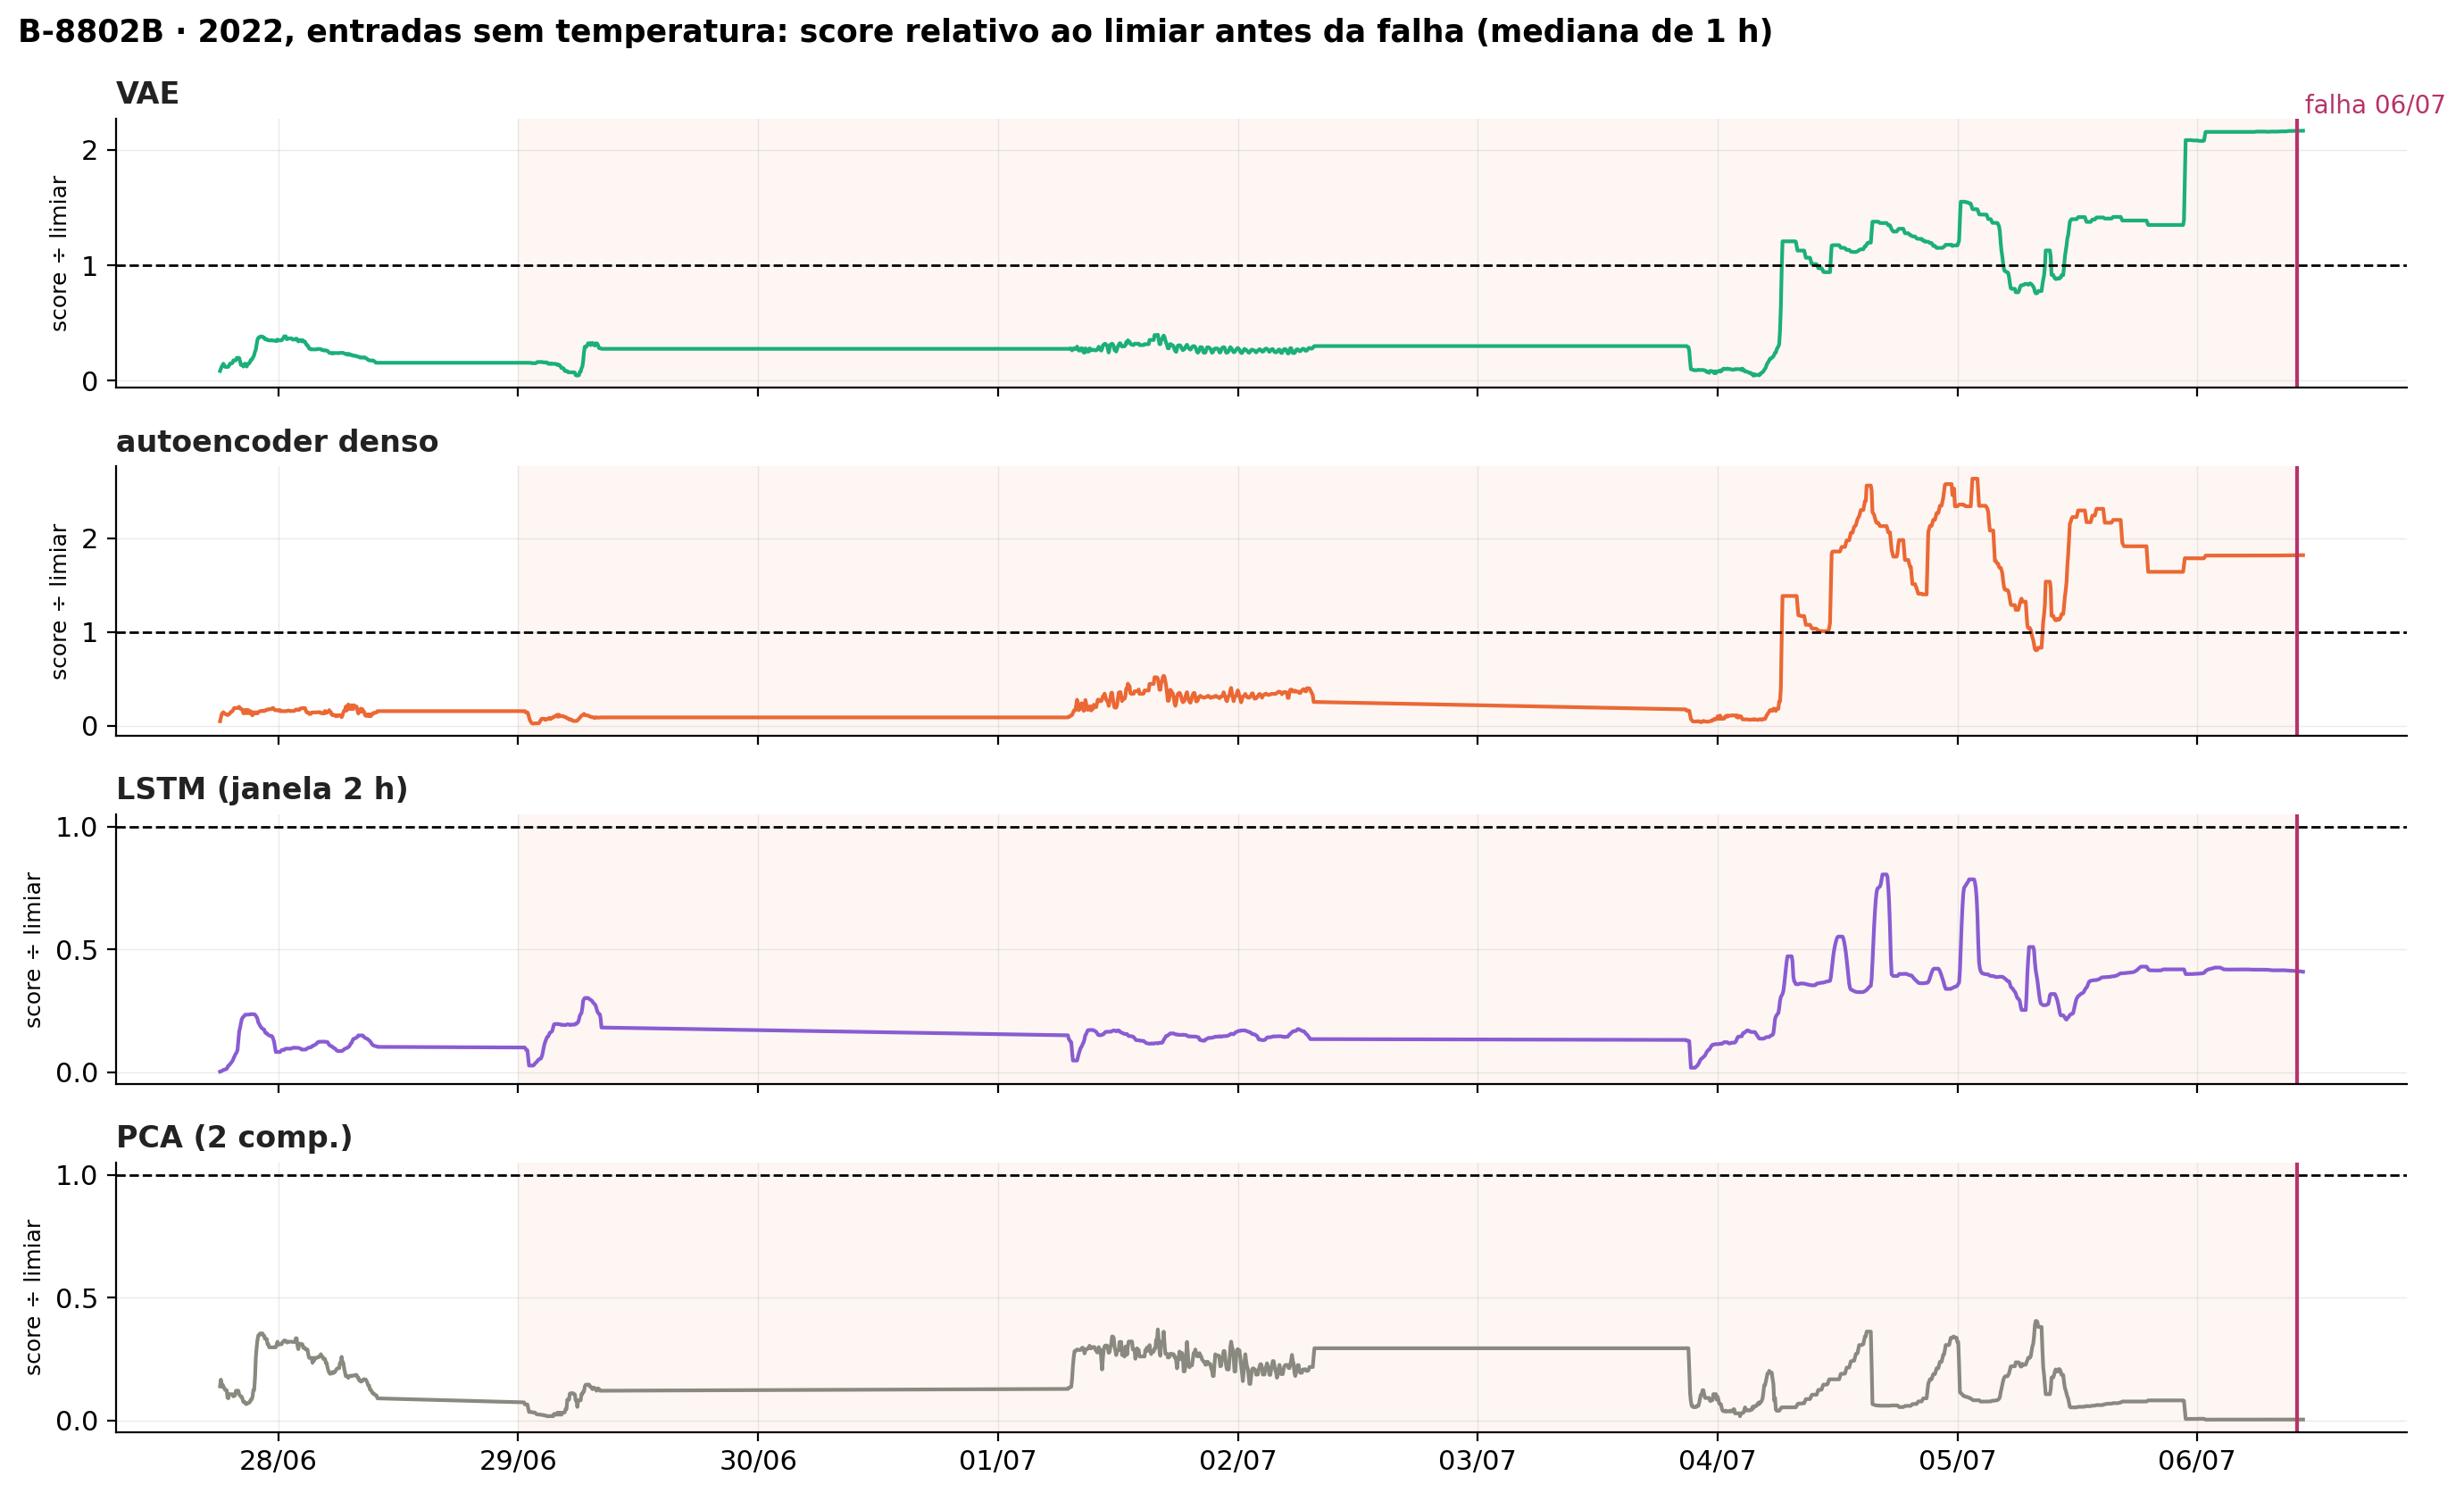

In [16]:
import arquiteturas_b8802b as ar
from transpetro_modelos.models.autoencoder import DenseAutoencoder, LSTMAutoencoder
var = "vib_press"
F = fx.features(ctx.pre, var); tr = F[(F.index >= fx.TS) & (F.index < fx.TE)]
esc = fx.Escala().fit(tr.iloc[:-int(len(tr) * 0.15)])
X, X22 = esc(F), esc(fx.features(ctx.pre22, var))
A = RAIZ / "results/arquiteturas/cands"
mods = {}
v = fx.build_model("vae", 4, dense_layers=[128, 64, 32], latent_dim=16)
v.load_state_dict(torch.load(R / "cands/vib_press/l128-64-32_lat16_lr0.0001_s0.pt", map_location="cpu")); v.eval()
mods["VAE"] = lambda Z: fx.erros(v, Z).mean(axis=1)
dn = DenseAutoencoder(4, [32, 16, 2]); dn.load_state_dict(torch.load(A / "vib_press__dense_s0.pt", map_location="cpu"))
mods["autoencoder denso"] = lambda Z: pd.Series(ar.erro_rede(dn, Z.to_numpy("float32")), index=Z.index)
ls = LSTMAutoencoder(4, hidden_dim=32, num_layers=1, seq_len=ar.L); ls.load_state_dict(torch.load(A / "vib_press__lstm_s0.pt", map_location="cpu"))
mods["LSTM (janela 2 h)"] = lambda Z: pd.Series(ar.erro_rede(ls, ar.janelas(Z)), index=Z.index)
from sklearn.decomposition import PCA
pca = PCA(2).fit(X.loc[tr.index[:-int(len(tr) * 0.15)]])
mods["PCA (2 comp.)"] = lambda Z: pd.Series(((Z.to_numpy() - pca.inverse_transform(pca.transform(Z))) ** 2).mean(axis=1), index=Z.index)
cores_m = {"VAE": "#1baf7a", "autoencoder denso": "#eb6834", "LSTM (janela 2 h)": "#8a5cd1", "PCA (2 comp.)": "#8a897f"}
fig, axes = plt.subplots(len(mods), 1, figsize=(14, 8.5), sharex=True)
for ax, (nome, f) in zip(axes, mods.items()):
    s_tr, s22 = f(X.loc[tr.index]), f(X22)
    thr = s_tr.mean() + 6.5 * s_tr.std()
    z = (s22 / thr).loc["2022-06-26":"2022-07-06 12:00"]
    ax.plot(z.index, z.rolling(12, min_periods=1).median(), color=cores_m[nome], lw=1.5)
    ax.axhline(1, color="black", ls="--", lw=1)
    ax.axvspan(fx.R0, fx.FAIL, color="#eb6834", alpha=0.06, lw=0)
    ax.axvline(fx.FAIL, color="#b8336a", lw=1.5)
    ax.set_ylabel("score ÷ limiar", fontsize=9)
    estilo(ax, nome)
axes[0].text(fx.FAIL, 1.02, " falha 06/07", transform=axes[0].get_xaxis_transform(), color="#b8336a", fontsize=10)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.suptitle("B-8802B · 2022, entradas sem temperatura: score relativo ao limiar antes da falha (mediana de 1 h)",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold")
fig.tight_layout()

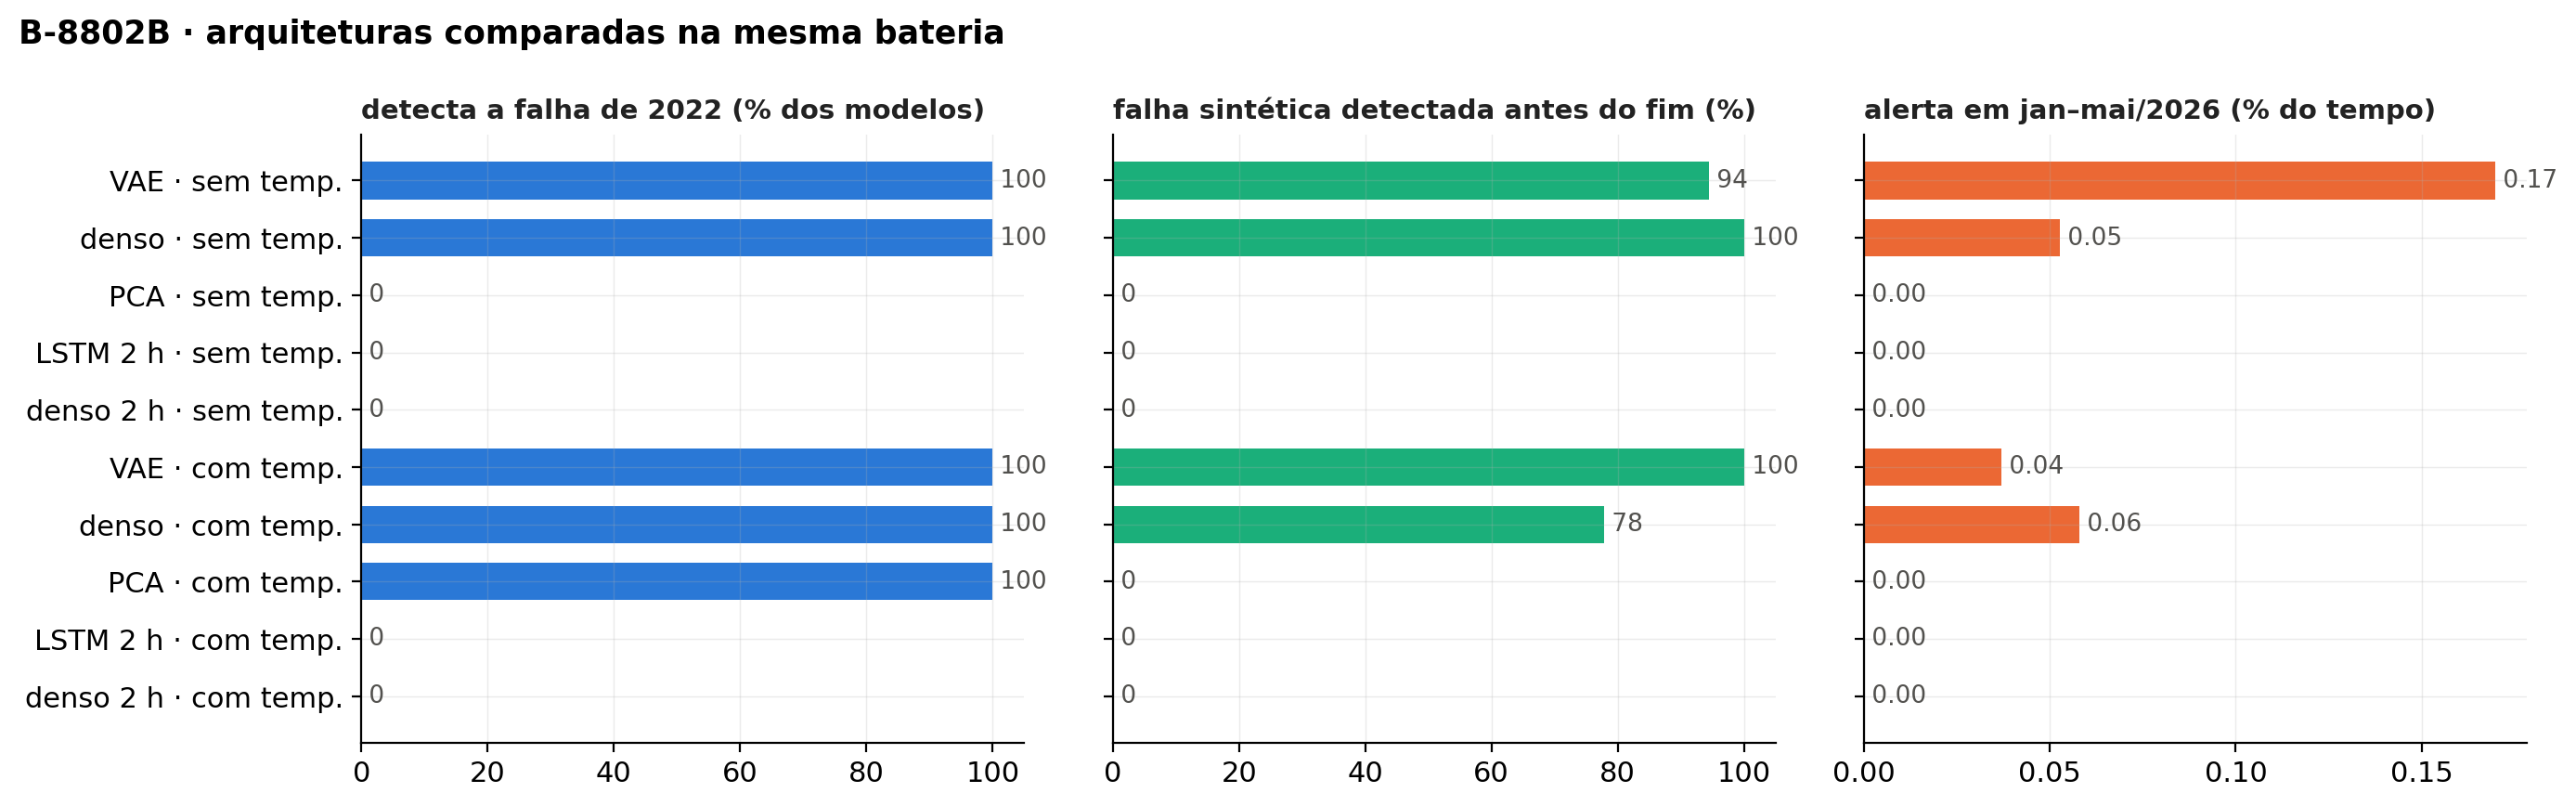

In [17]:
arq = pd.read_csv(RAIZ / "results/arquiteturas/avaliacao.csv")
ref = av[av.variante.isin(["base", "vib_press"])].assign(variante=lambda x: x.variante + "·vae")
d = pd.concat([arq, ref]); d = d[d.modo == "bruto"]
s100 = [c for c in d if c.startswith("sint100")]
d["sint"] = (d[s100] > 0).sum(axis=1) / d[s100].notna().sum(axis=1) * 100
d["v2022"] = d.falha2022_dias.notna() * 100
g = d.groupby("variante").agg(sint=("sint", "mean"), v2022=("v2022", "mean"), janmai=("alerta_jan-mai26_%", "median"))
ordem = ["vib_press·vae", "vib_press·dense", "vib_press·pca2", "vib_press·lstm", "vib_press·dense_janela",
         "base·vae", "base·dense", "base·pca2", "base·lstm", "base·dense_janela"]
g = g.reindex([o for o in ordem if o in g.index])
rot = {"vae": "VAE", "dense": "denso", "pca2": "PCA", "lstm": "LSTM 2 h", "dense_janela": "denso 2 h"}
nomes = [f"{rot[i.split('·')[1]]} · {'sem temp.' if i.startswith('vib') else 'com temp.'}" for i in g.index]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
for ax, col, tit, cor in [(axes[0], "v2022", "detecta a falha de 2022 (% dos modelos)", "#2a78d6"),
                          (axes[1], "sint", "falha sintética detectada antes do fim (%)", "#1baf7a"),
                          (axes[2], "janmai", "alerta em jan–mai/2026 (% do tempo)", "#eb6834")]:
    ax.barh(range(len(g)), g[col], color=cor, height=0.65)
    for i, val in enumerate(g[col]):
        ax.text(val, i, f" {val:.0f}" if col != "janmai" else f" {val:.2f}", va="center", fontsize=9.5, color=TEXTO)
    estilo(ax, tit); ax.set_title(tit, loc="left", fontsize=10.5, fontweight="bold")
axes[0].set_yticks(range(len(g)), nomes); axes[0].invert_yaxis()
fig.suptitle("B-8802B · arquiteturas comparadas na mesma bateria", x=0.01, ha="left", fontsize=12.5, fontweight="bold")
fig.tight_layout()

**Leitura:**
- **LSTM e denso com janela de 2 h ficam cegos**: o score quase não se mexe antes da falha. Reconstruir a janela inteira
  "dilui" a subida da vibração (e o erro médio da janela ficou dominado pelo ruído de 5 em 5 min). Nesta configuração,
  não vale seguir.
- **PCA** sem temperatura não enxerga a falha de 2022 (o score nem chega perto do limiar); com temperatura detecta 2022,
  mas nenhuma falha sintética. Uma reconstrução linear não basta.
- **O autoencoder denso simples** fica no nível do VAE em sensibilidade, com menos alerta em janeiro — por isso ele
  entrou na comparação completa da seção 7 ("sem temperatura · denso").

## 10. Conclusões

**O que deu certo**
1. **Tirar a temperatura do modelo** (vibração + pressões): erro estável em 2026, mesma sensibilidade (falha de 2022 e
   sintética), e alerta só nos episódios de vibração de janeiro — de forma mais consistente que o modelo atual.
   Também deixa o monitor de drift sem o falso sinal do "erro subindo" causado pela temperatura.
2. **A temperatura não dá sensibilidade ao modelo** (seção 6): vai para um detector próprio (M8 ou regra de taxa).
3. **VAE continua sendo a melhor rede.** O autoencoder denso empatou com 3 sementes, mas na grade completa (12
   modelos) é menos estável; PCA e modelos com janela de 2 h ficam cegos (seções 7–9).
4. **Suavizar o score** deixa a curva legível; para alarmar menos precisa de outra regra de limiar.

**O que não deu certo**
- só temperaturas, espectro das vibrações, ΔT com score bruto, só vibração (seções 2–5);
- PCA, modelos com janela de 2 h e autoencoder denso (seções 7–9);
- antes (task ea9fd4cc): diferença mancal − motor.

**Decisão pendente:** o episódio de **10–12/01/2026** (seção 7). Real → a receita sem temperatura é melhor e vira a
pipeline do B-8802B. Não real → mantém o modelo atual (ou o critério de alerta da bateria decide entre os candidatos).

**Cuidados:** 2026 não tem rótulo completo; a falha sintética usa a assinatura de uma única falha (2022, acoplamento),
dominada por vibração; as arquiteturas com janela foram testadas em uma configuração só.